In [1]:
import os
import pandas as pd

CSV_YOLU = "data/diabetes.csv"
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
SUTUNLAR = ["Gebelik", "Glukoz", "KanBasinci", "DeriKalinligi", "Insulin", "VKI", "DiyabetSoyagaci", "Yas", "Sonuc"]

if not os.path.exists(CSV_YOLU):
    os.makedirs("data", exist_ok=True)
    pd.read_csv(URL, header=None, names=SUTUNLAR).to_csv(CSV_YOLU, index=False)
    print("Veri seti indirildi ve CSV olarak kaydedildi.")
else:
    print("Veri seti mevcut:", CSV_YOLU)

Veri seti mevcut: data/diabetes.csv


In [2]:
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.contingency_tables import mcnemar

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, cross_validate, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree
from sklearn.inspection import permutation_importance
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score,
                             balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score, matthews_corrcoef,
                             cohen_kappa_score)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid", palette="Set2")
%matplotlib inline

df = pd.read_csv(CSV_YOLU)
print("Veri seti başarıyla yüklendi.")
df.head(10)

Veri seti başarıyla yüklendi.


,Gebelik,Glukoz,KanBasinci,DeriKalinligi,Insulin,VKI,DiyabetSoyagaci,Yas,Sonuc
0,6,148,72,35,0,33.6000,0.6270,50,1
1,1,85,66,29,0,26.6000,0.3510,31,0
2,8,183,64,0,0,23.3000,0.6720,32,1
3,1,89,66,23,94,28.1000,0.1670,21,0
4,0,137,40,35,168,43.1000,2.2880,33,1
5,5,116,74,0,0,25.6000,0.2010,30,0
6,3,78,50,32,88,31.0000,0.2480,26,1
7,10,115,0,0,0,35.3000,0.1340,29,0
8,2,197,70,45,543,30.5000,0.1580,53,1
9,8,125,96,0,0,0.0000,0.2320,54,1


In [3]:
df.tail()

,Gebelik,Glukoz,KanBasinci,DeriKalinligi,Insulin,VKI,DiyabetSoyagaci,Yas,Sonuc
763,10,101,76,48,180,32.9000,0.1710,63,0
764,2,122,70,27,0,36.8000,0.3400,27,0
765,5,121,72,23,112,26.2000,0.2450,30,0
766,1,126,60,0,0,30.1000,0.3490,47,1
767,1,93,70,31,0,30.4000,0.3150,23,0


In [4]:
OZELLIKLER = [k for k in df.columns if k != "Sonuc"]
print(f"Gözlem sayısı           : {df.shape[0]}")
print(f"Değişken sayısı         : {df.shape[1]} ({len(OZELLIKLER)} özellik + hedef)")
print(f"Görünür eksik değer     : {df.isna().sum().sum()}")
print(f"Tekrarlanan satır sayısı: {df.duplicated().sum()}")
print()
df.info()

Gözlem sayısı           : 768
Değişken sayısı         : 9 (8 özellik + hedef)
Görünür eksik değer     : 0
Tekrarlanan satır sayısı: 0

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Gebelik          768 non-null    int64  
 1   Glukoz           768 non-null    int64  
 2   KanBasinci       768 non-null    int64  
 3   DeriKalinligi    768 non-null    int64  
 4   Insulin          768 non-null    int64  
 5   VKI              768 non-null    float64
 6   DiyabetSoyagaci  768 non-null    float64
 7   Yas              768 non-null    int64  
 8   Sonuc            768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,Sıfır (eksik) sayısı,Eksik oranı (%)
Glukoz,5,0.6510
KanBasinci,35,4.5573
DeriKalinligi,227,29.5573
Insulin,374,48.6979
VKI,11,1.4323


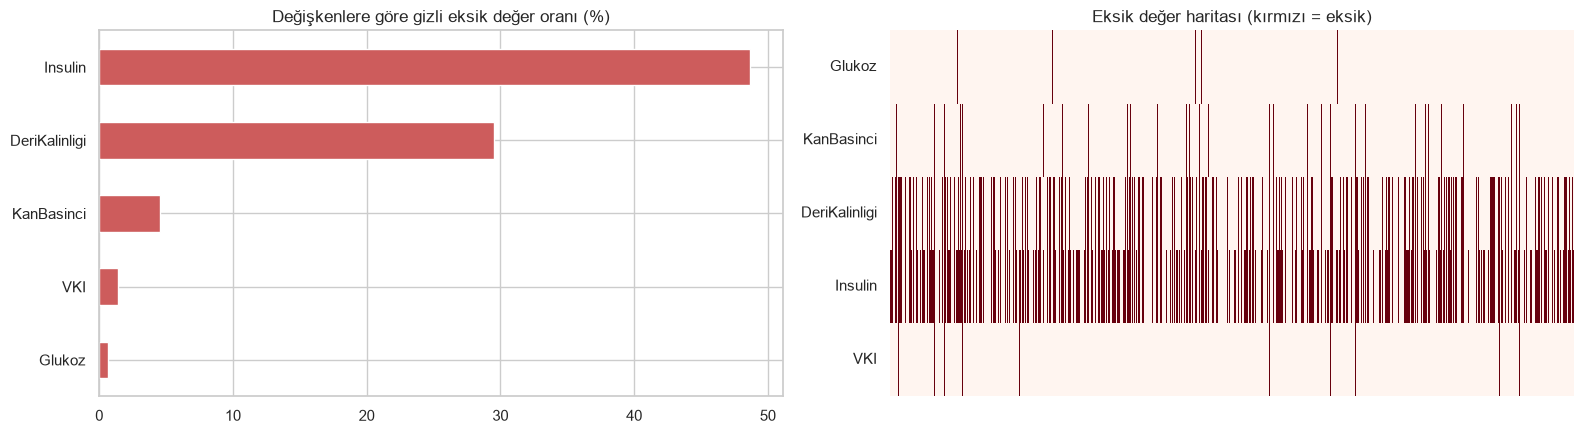

En az bir eksik değeri olan gözlem: 376 / 768


In [5]:
SIFIR_EKSIK = ["Glukoz", "KanBasinci", "DeriKalinligi", "Insulin", "VKI"]
eksik = pd.DataFrame({"Sıfır (eksik) sayısı": (df[SIFIR_EKSIK] == 0).sum(),
                      "Eksik oranı (%)": (df[SIFIR_EKSIK] == 0).mean() * 100})
display(eksik)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
eksik["Eksik oranı (%)"].sort_values().plot.barh(ax=axes[0], color="indianred")
axes[0].set_title("Değişkenlere göre gizli eksik değer oranı (%)")
sns.heatmap((df[SIFIR_EKSIK] == 0).T, cbar=False, cmap="Reds", ax=axes[1], xticklabels=False)
axes[1].set_title("Eksik değer haritası (kırmızı = eksik)")
plt.tight_layout()
plt.show()

veri = df.copy()
veri[SIFIR_EKSIK] = veri[SIFIR_EKSIK].replace(0, np.nan)
print(f"En az bir eksik değeri olan gözlem: {veri.isna().any(axis=1).sum()} / {len(veri)}")

In [6]:
pd.DataFrame({k: veri.groupby(veri[k].isna())["Sonuc"].mean() * 100 for k in ["DeriKalinligi", "Insulin"]}) \
  .rename(index={False: "Ölçülmüş", True: "Eksik"}).rename_axis("Diyabet oranı (%)")

,DeriKalinligi,Insulin
Diyabet oranı (%),,
Ölçülmüş,33.2717,32.9949
Eksik,38.7665,36.8984


,Frekans,Oran (%)
Diyabet değil (0),500,65.1042
Diyabet (1),268,34.8958


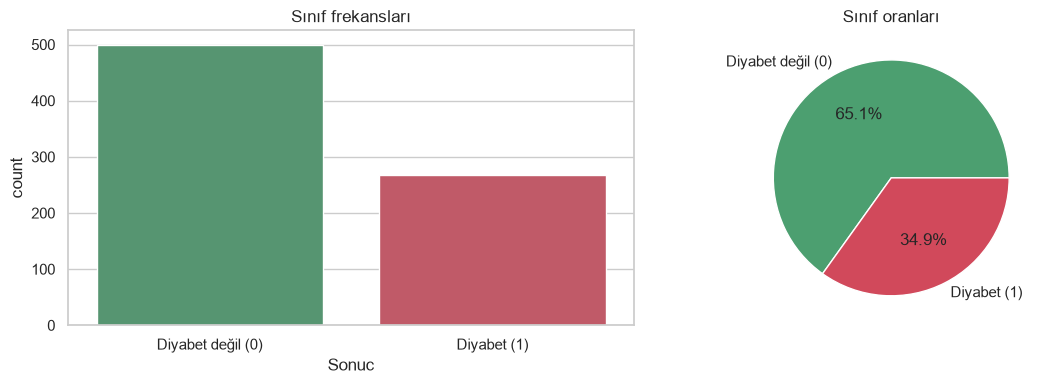

In [7]:
SINIFLAR = ["Diyabet değil (0)", "Diyabet (1)"]
RENK = {0: "#4C9F70", 1: "#D1495B"}
dagilim = pd.DataFrame({"Frekans": veri["Sonuc"].value_counts().sort_index(),
                        "Oran (%)": veri["Sonuc"].value_counts(normalize=True).sort_index() * 100})
dagilim.index = SINIFLAR
display(dagilim)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=veri, x="Sonuc", hue="Sonuc", palette=RENK, ax=axes[0], legend=False)
axes[0].set_xticks([0, 1], SINIFLAR)
axes[0].set_title("Sınıf frekansları")
axes[1].pie(dagilim["Frekans"], labels=SINIFLAR, autopct="%1.1f%%", colors=[RENK[0], RENK[1]])
axes[1].set_title("Sınıf oranları")
plt.tight_layout()
plt.show()

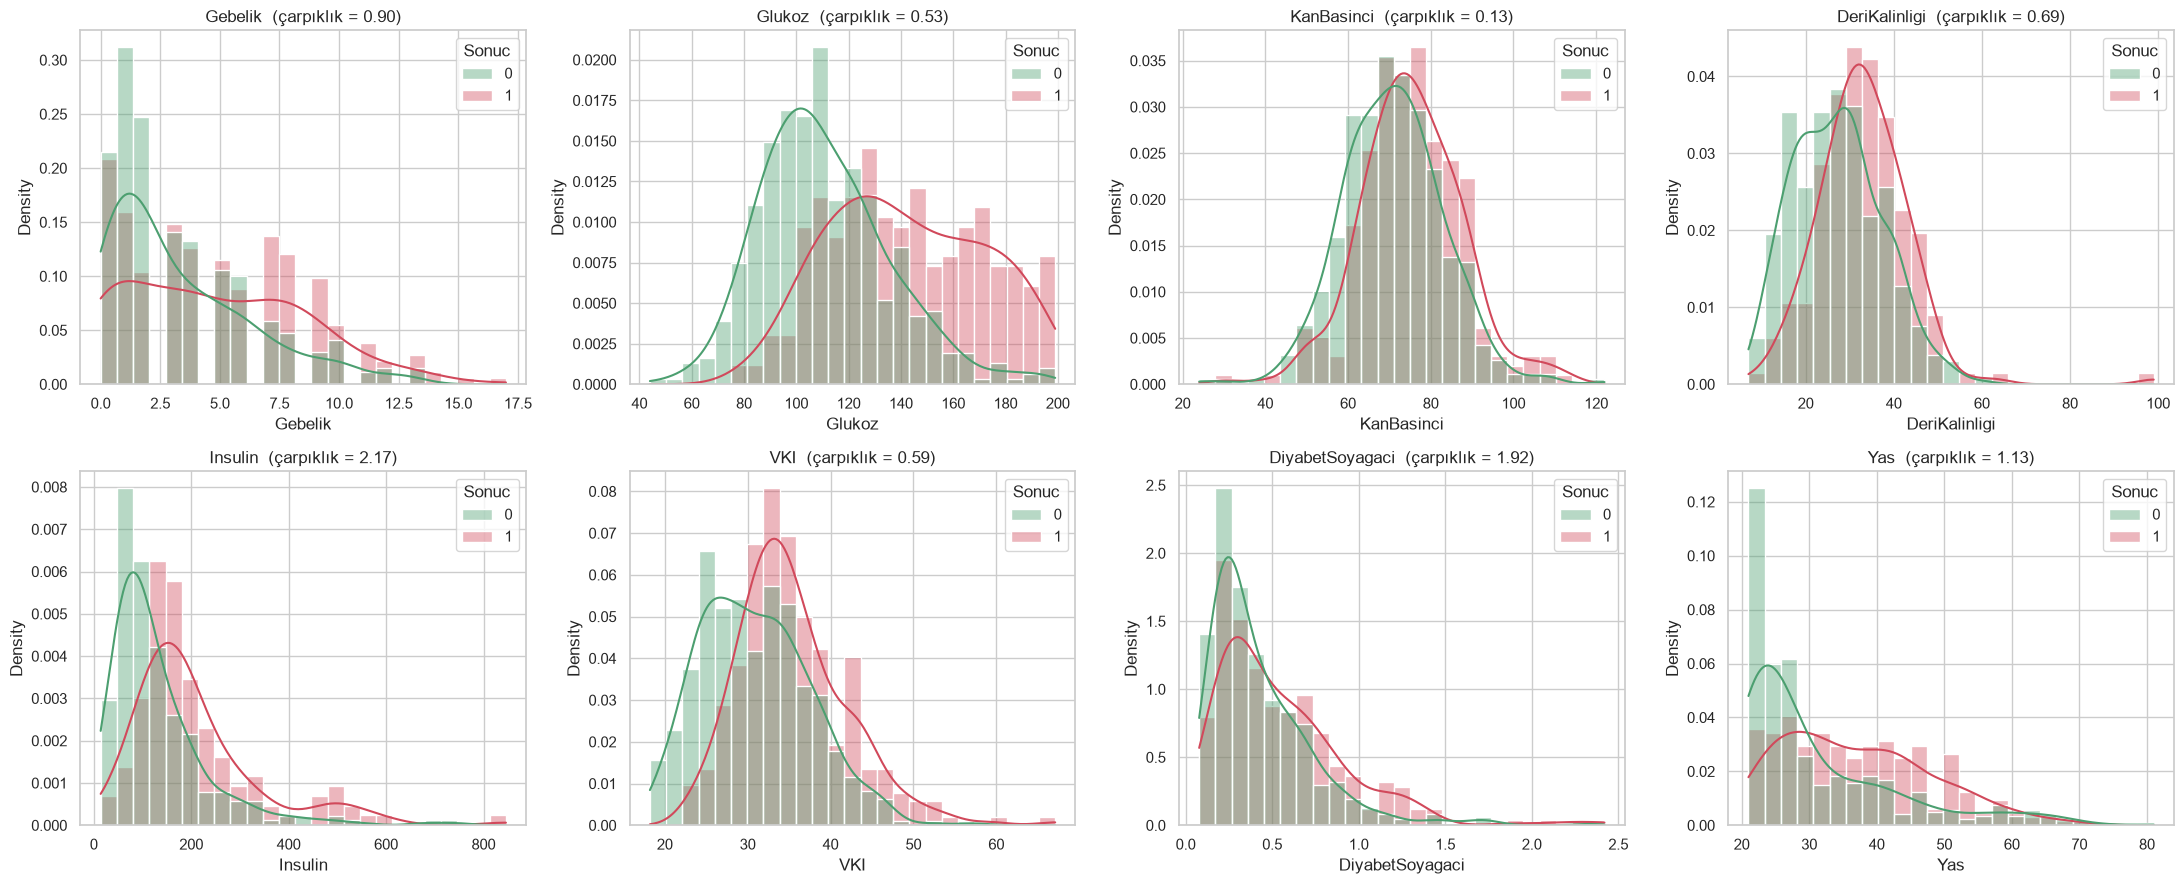

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for ax, kol in zip(axes.flat, OZELLIKLER):
    sns.histplot(data=veri, x=kol, hue="Sonuc", kde=True, palette=RENK, stat="density", common_norm=False,
                 bins=25, ax=ax, alpha=0.4)
    ax.set_title(f"{kol}  (çarpıklık = {veri[kol].skew():.2f})")
plt.tight_layout()
plt.show()

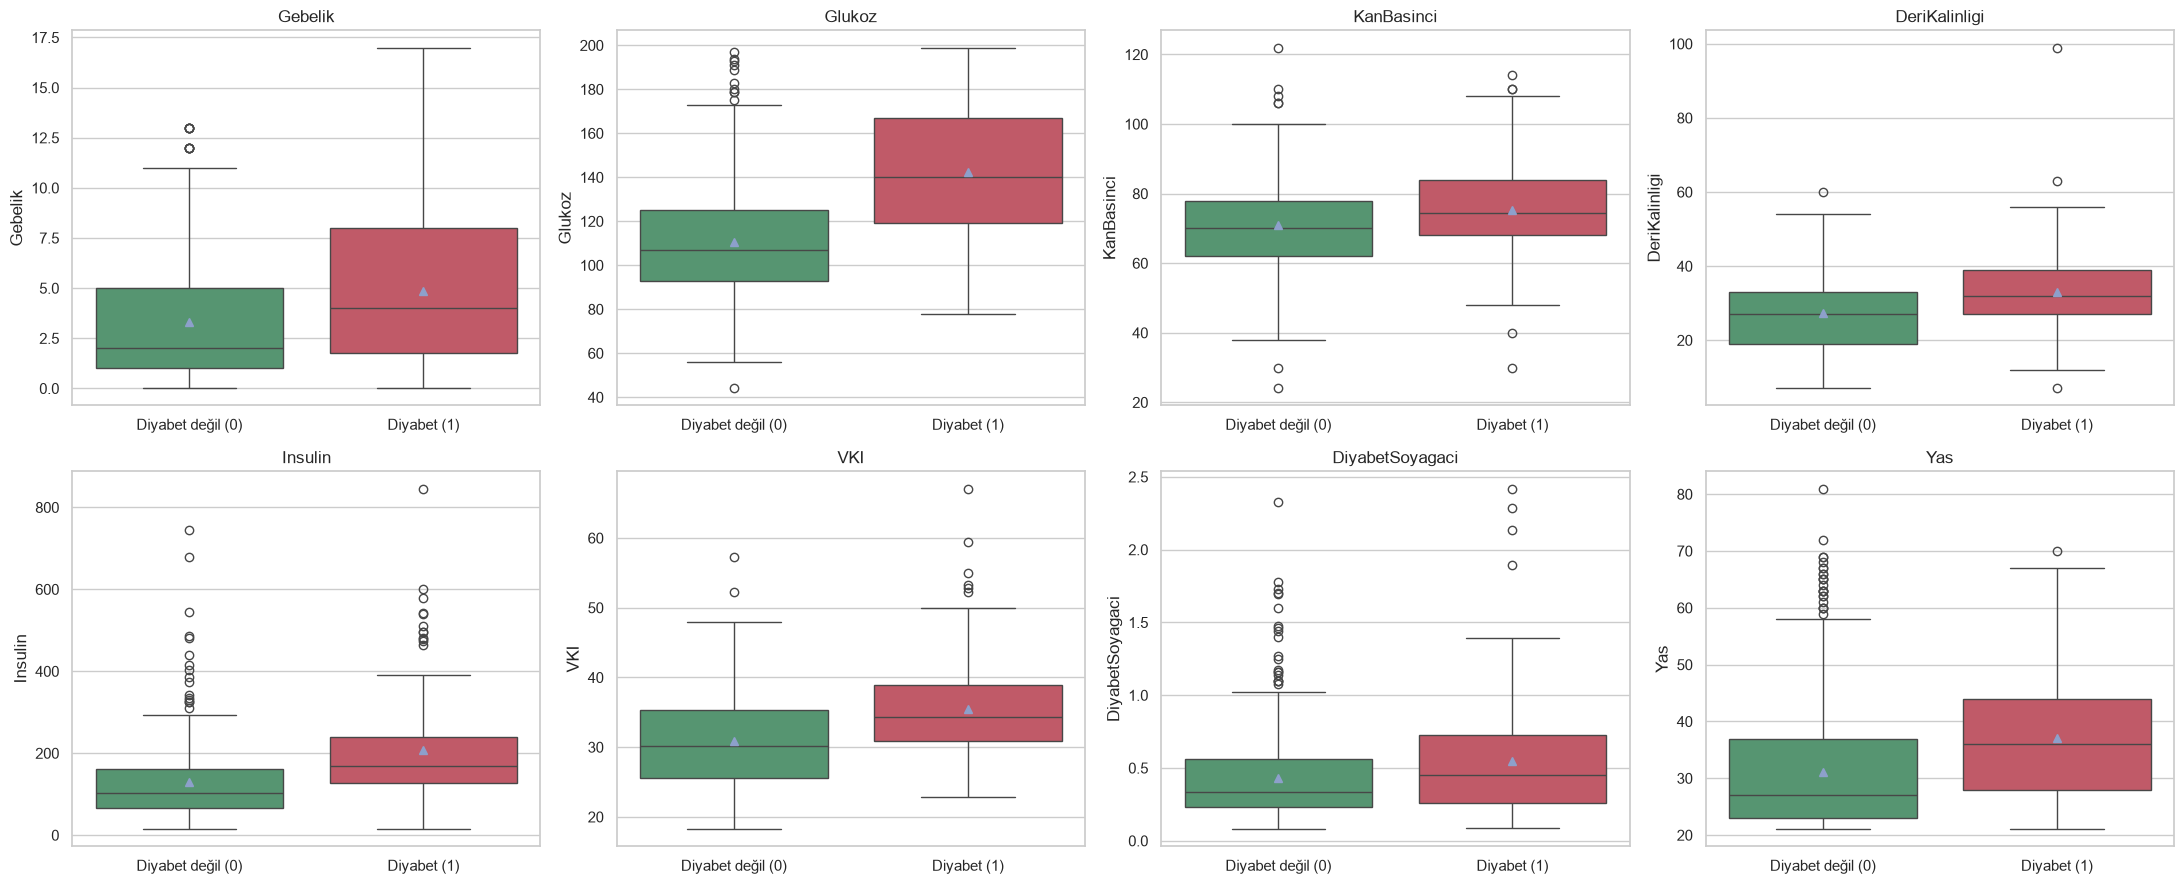

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for ax, kol in zip(axes.flat, OZELLIKLER):
    sns.boxplot(data=veri, x="Sonuc", y=kol, hue="Sonuc", palette=RENK, ax=ax, legend=False, showmeans=True)
    ax.set_xticks([0, 1], SINIFLAR)
    ax.set_xlabel("")
    ax.set_title(kol)
plt.tight_layout()
plt.show()

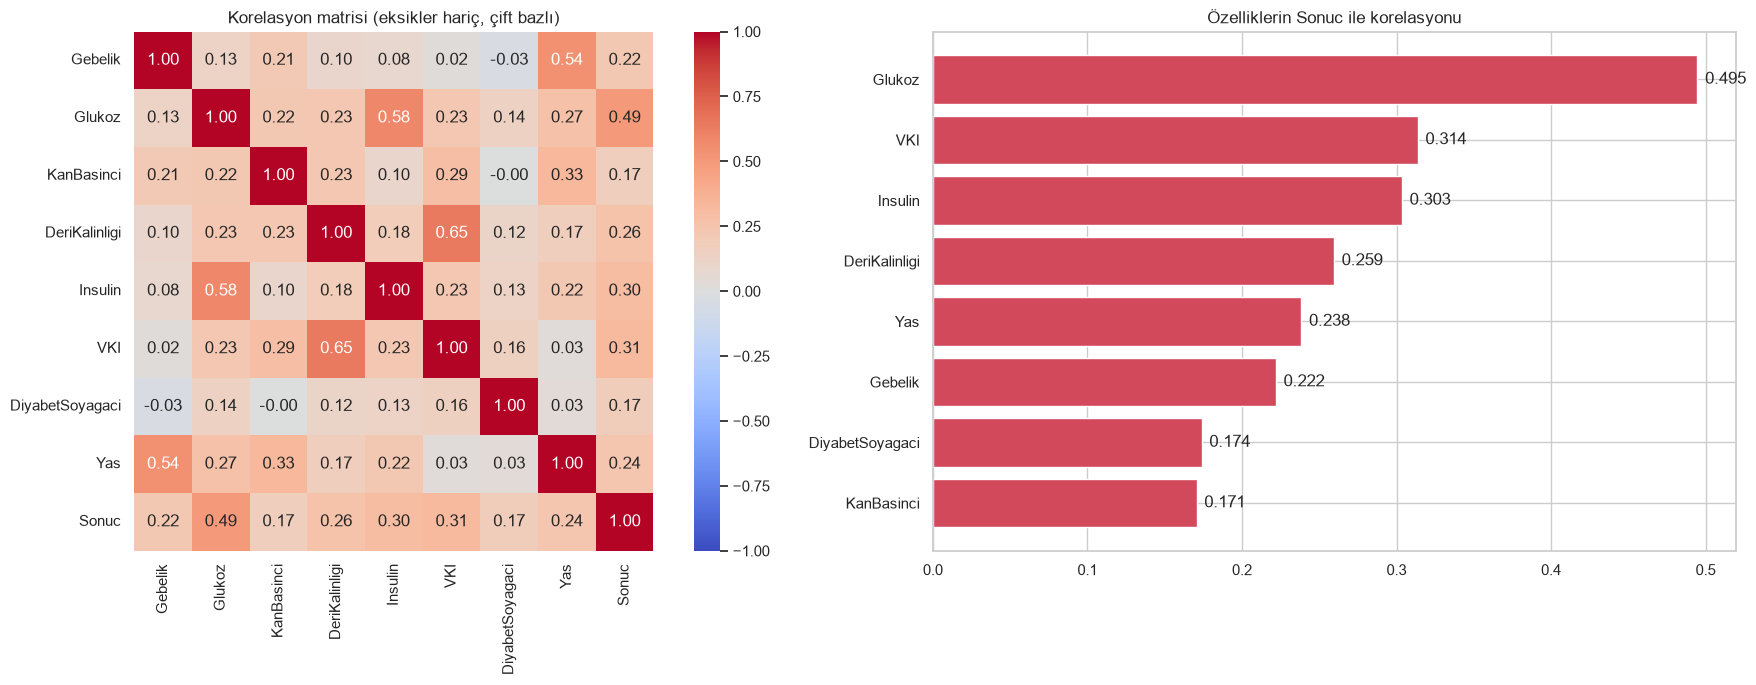

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(19, 7))
sns.heatmap(veri.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=axes[0])
axes[0].set_title("Korelasyon matrisi (eksikler hariç, çift bazlı)")
hk = veri[OZELLIKLER].corrwith(veri["Sonuc"]).sort_values()
axes[1].barh(hk.index, hk.values, color=[RENK[1] if v > 0 else RENK[0] for v in hk.values])
for i, v in enumerate(hk.values):
    axes[1].text(v + 0.005, i, f"{v:.3f}", va="center")
axes[1].set_title("Özelliklerin Sonuc ile korelasyonu")
plt.tight_layout()
plt.show()

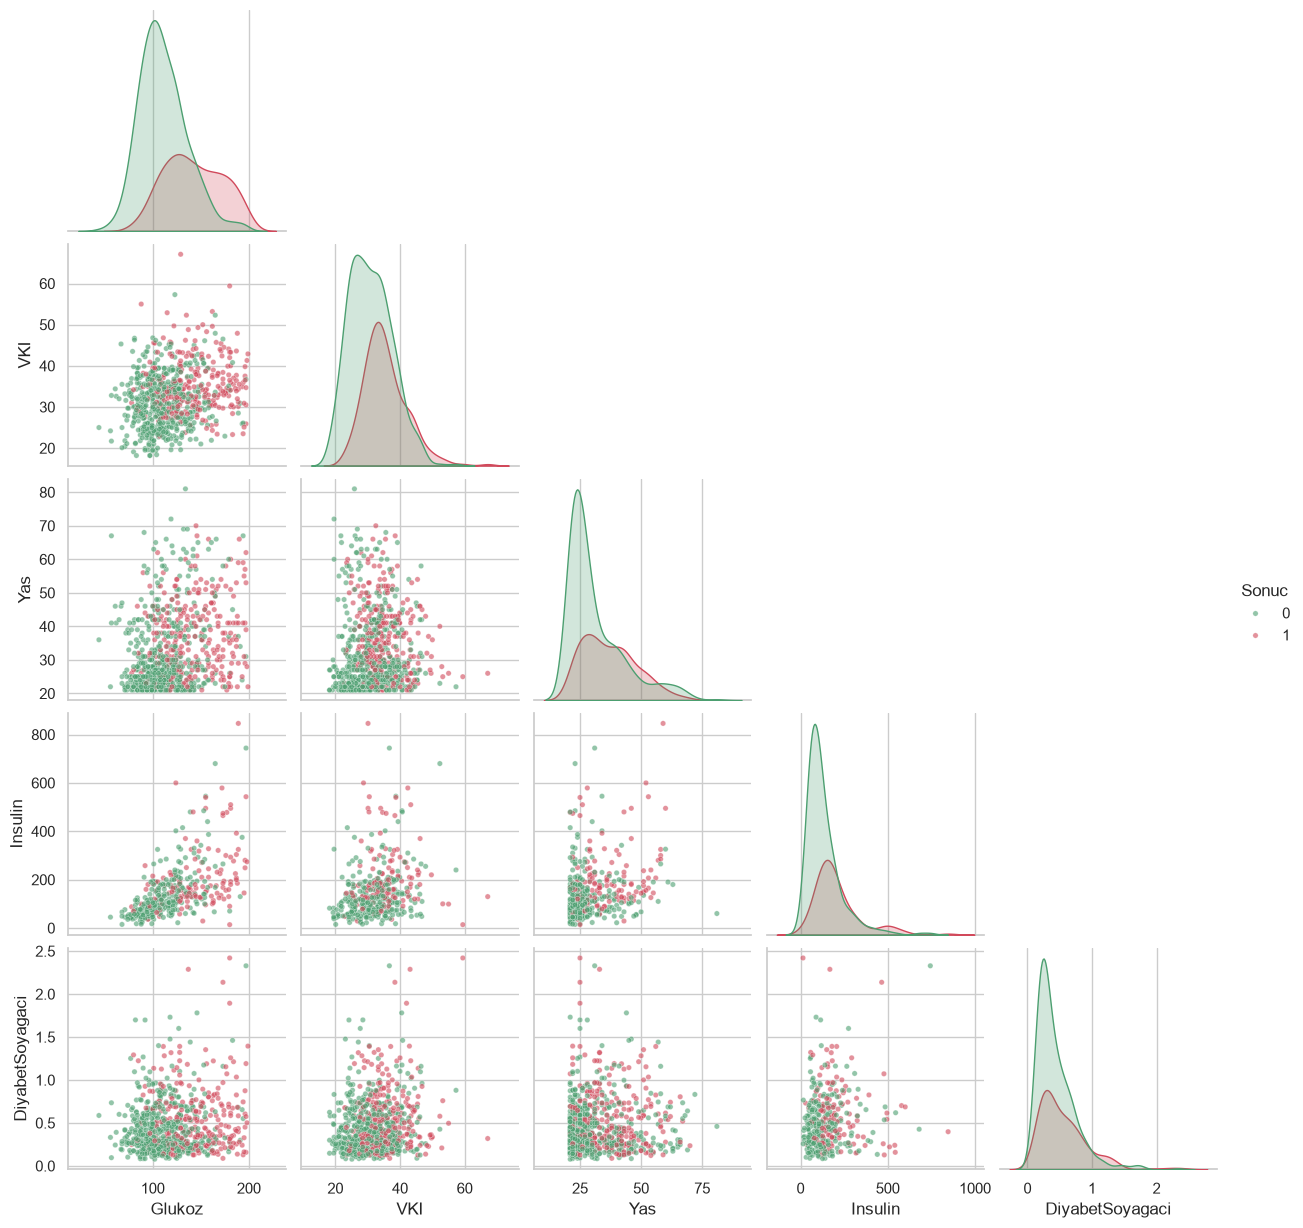

In [11]:
sns.pairplot(veri, vars=["Glukoz", "VKI", "Yas", "Insulin", "DiyabetSoyagaci"], hue="Sonuc", palette=RENK,
             corner=True, plot_kws={"s": 15, "alpha": 0.6})
plt.show()

In [12]:
veri[OZELLIKLER].describe().T

,count,mean,std,min,25%,50%,75%,max
Gebelik,768.0000,3.8451,3.3696,0.0000,1.0000,3.0000,6.0000,17.0000
Glukoz,763.0000,121.6868,30.5356,44.0000,99.0000,117.0000,141.0000,199.0000
KanBasinci,733.0000,72.4052,12.3822,24.0000,64.0000,72.0000,80.0000,122.0000
DeriKalinligi,541.0000,29.1534,10.4770,7.0000,22.0000,29.0000,36.0000,99.0000
Insulin,394.0000,155.5482,118.7759,14.0000,76.2500,125.0000,190.0000,846.0000
VKI,757.0000,32.4575,6.9250,18.2000,27.5000,32.3000,36.6000,67.1000
DiyabetSoyagaci,768.0000,0.4719,0.3313,0.0780,0.2437,0.3725,0.6262,2.4200
Yas,768.0000,33.2409,11.7602,21.0000,24.0000,29.0000,41.0000,81.0000


In [13]:
def aciklayici_tablo(d):
    satirlar = {}
    for kol in d.columns:
        s = d[kol].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        satirlar[kol] = {
            "n (geçerli)": s.count(),
            "Eksik": d[kol].isna().sum(),
            "Ortalama": s.mean(),
            "Medyan": s.median(),
            "Mod": s.mode().iloc[0],
            "Std. Sapma": s.std(),
            "Varyans": s.var(),
            "Değişim Kats. (%)": s.std() / s.mean() * 100,
            "Minimum": s.min(),
            "Q1": q1,
            "Q3": q3,
            "Maksimum": s.max(),
            "IQR": iqr,
            "Çarpıklık": s.skew(),
            "Basıklık": s.kurt(),
            "Aykırı (1.5·IQR)": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
        }
    return pd.DataFrame(satirlar).T

aciklayici_tablo(veri[OZELLIKLER])

,n (geçerli),Eksik,Ortalama,Medyan,Mod,Std. Sapma,Varyans,Değişim Kats. (%),Minimum,Q1,Q3,Maksimum,IQR,Çarpıklık,Basıklık,Aykırı (1.5·IQR)
Gebelik,768.0000,0.0000,3.8451,3.0000,1.0000,3.3696,11.3541,87.6341,0.0000,1.0000,6.0000,17.0000,5.0000,0.9017,0.1592,4.0000
Glukoz,763.0000,5.0000,121.6868,117.0000,99.0000,30.5356,932.4254,25.0936,44.0000,99.0000,141.0000,199.0000,42.0000,0.5310,-0.2770,0.0000
KanBasinci,733.0000,35.0000,72.4052,72.0000,70.0000,12.3822,153.3178,17.1012,24.0000,64.0000,80.0000,122.0000,16.0000,0.1342,0.9112,14.0000
DeriKalinligi,541.0000,227.0000,29.1534,29.0000,32.0000,10.4770,109.7672,35.9374,7.0000,22.0000,36.0000,99.0000,14.0000,0.6906,2.9355,3.0000
Insulin,394.0000,374.0000,155.5482,125.0000,105.0000,118.7759,14107.7038,76.3595,14.0000,76.2500,190.0000,846.0000,113.7500,2.1665,6.3705,24.0000
VKI,757.0000,11.0000,32.4575,32.3000,32.0000,6.9250,47.9555,21.3356,18.2000,27.5000,36.6000,67.1000,9.1000,0.5940,0.8634,8.0000
DiyabetSoyagaci,768.0000,0.0000,0.4719,0.3725,0.2540,0.3313,0.1098,70.2151,0.0780,0.2437,0.6262,2.4200,0.3825,1.9199,5.5950,29.0000
Yas,768.0000,0.0000,33.2409,29.0000,22.0000,11.7602,138.3030,35.3788,21.0000,24.0000,41.0000,81.0000,17.0000,1.1296,0.6432,9.0000


In [14]:
grup = []
for kol in OZELLIKLER:
    a = veri.loc[veri["Sonuc"] == 0, kol].dropna()
    b = veri.loc[veri["Sonuc"] == 1, kol].dropna()
    u, p = stats.mannwhitneyu(a, b)
    d = (b.mean() - a.mean()) / np.sqrt((a.var() + b.var()) / 2)
    grup.append({"Özellik": kol, "Diyabet değil – ort.": a.mean(), "Diyabet değil – medyan": a.median(),
                 "Diyabet – ort.": b.mean(), "Diyabet – medyan": b.median(), "Mann-Whitney p": p, "Cohen d": d})
pd.DataFrame(grup).set_index("Özellik").sort_values("Cohen d", ascending=False)

,Diyabet değil – ort.,Diyabet değil – medyan,Diyabet – ort.,Diyabet – medyan,Mann-Whitney p,Cohen d
Özellik,,,,,,
Glukoz,110.6439,107.0000,142.3195,140.0000,0.0000,1.1605
VKI,30.8597,30.1000,35.4068,34.3000,0.0000,0.6902
Insulin,130.2879,102.5000,206.8462,169.5000,0.0000,0.6457
DeriKalinligi,27.2355,27.0000,33.0000,32.0000,0.0000,0.5664
Yas,31.1900,27.0000,37.0672,36.0000,0.0000,0.5190
Gebelik,3.2980,2.0000,4.8657,4.0000,0.0000,0.4613
KanBasinci,70.8773,70.0000,75.3214,74.5000,0.0000,0.3634
DiyabetSoyagaci,0.4297,0.3360,0.5505,0.4490,0.0000,0.3576


In [15]:
X = veri[OZELLIKLER]
y = veri["Sonuc"]
X_egitim, X_test, y_egitim, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pd.DataFrame({"Gözlem": [len(y_egitim), len(y_test)],
              "Diyabet değil": [(y_egitim == 0).sum(), (y_test == 0).sum()],
              "Diyabet": [(y_egitim == 1).sum(), (y_test == 1).sum()],
              "Diyabet oranı (%)": [y_egitim.mean() * 100, y_test.mean() * 100]}, index=["Eğitim", "Test"])

,Gözlem,Diyabet değil,Diyabet,Diyabet oranı (%)
Eğitim,576,375,201,34.8958
Test,192,125,67,34.8958


In [16]:
YONTEMLER = {
    "k-NN": {
        "pipeline": Pipeline([("doldur", SimpleImputer(strategy="median")), ("olcek", StandardScaler()),
                              ("model", KNeighborsClassifier())]),
        "izgara": {"model__n_neighbors": list(range(1, 52, 2)), "model__weights": ["uniform", "distance"],
                   "model__p": [1, 2]},
    },
    "SVM": {
        "pipeline": Pipeline([("doldur", SimpleImputer(strategy="median")), ("olcek", StandardScaler()),
                              ("model", SVC(kernel="rbf"))]),
        "izgara": {"model__C": [0.01, 0.1, 1, 10, 100], "model__gamma": [0.001, 0.01, 0.1, 1]},
    },
    "Rastgele Orman": {
        "pipeline": Pipeline([("doldur", SimpleImputer(strategy="median")),
                              ("model", RandomForestClassifier(n_estimators=300, random_state=42))]),
        "izgara": {"model__max_depth": [3, 5, 8, None], "model__min_samples_leaf": [1, 3, 5, 10],
                   "model__max_features": ["sqrt", 0.5]},
    },
}
RENK_YONTEM = {"k-NN": "tab:blue", "SVM": "tab:orange", "Rastgele Orman": "tab:green"}

aramalar, modeller, sureler = {}, {}, {}
for ad, y_ in YONTEMLER.items():
    t0 = time.perf_counter()
    gs = GridSearchCV(y_["pipeline"], y_["izgara"], cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_egitim, y_egitim)
    sureler[ad] = time.perf_counter() - t0
    aramalar[ad], modeller[ad] = gs, gs.best_estimator_

pd.DataFrame({ad: {"En iyi parametreler": {k.replace("model__", ""): v for k, v in gs.best_params_.items()},
                   "Denenen kombinasyon": len(gs.cv_results_["params"]),
                   "CV ROC-AUC (en iyi)": round(gs.best_score_, 4),
                   "Arama süresi (sn)": round(sureler[ad], 2)} for ad, gs in aramalar.items()}).T

,En iyi parametreler,Denenen kombinasyon,CV ROC-AUC (en iyi),Arama süresi (sn)
k-NN,"{'n_neighbors': 21, 'p': 2, 'weights': 'distan...",104,0.8342,3.9300
SVM,"{'C': 100, 'gamma': 0.001}",20,0.8389,0.3500
Rastgele Orman,"{'max_depth': 5, 'max_features': 0.5, 'min_sam...",32,0.8293,12.9100


In [17]:
def skor(model, X_):
    return model.predict_proba(X_)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_)

tahminler, skorlar = {}, {}
for ad, m in modeller.items():
    tahminler[ad] = m.predict(X_test)
    skorlar[ad] = skor(m, X_test)

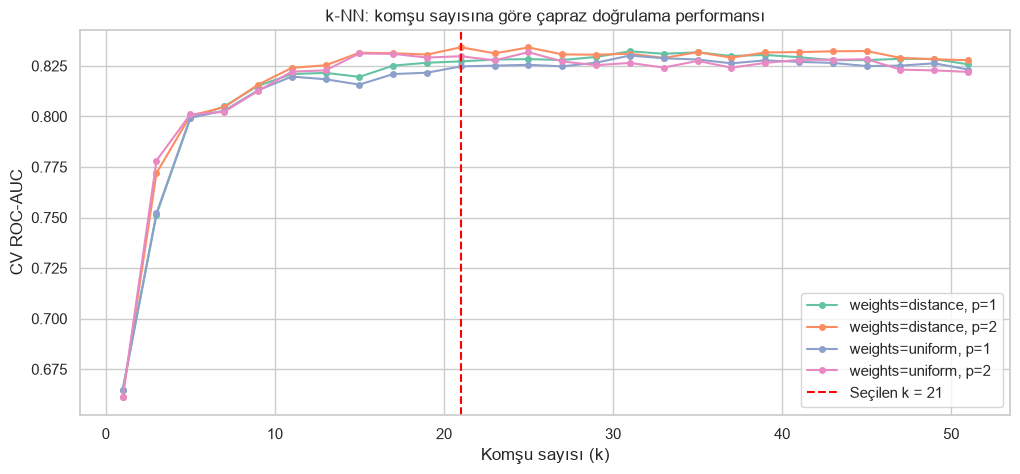

In [18]:
s = pd.DataFrame(aramalar["k-NN"].cv_results_)
s = s.rename(columns=lambda c: c.replace("param_model__", ""))
fig, ax = plt.subplots(figsize=(12, 5))
for (w, p), g in s.groupby(["weights", "p"]):
    ax.plot(g["n_neighbors"], g["mean_test_score"], "o-", markersize=4, label=f"weights={w}, p={p}")
en = aramalar["k-NN"].best_params_
ax.axvline(en["model__n_neighbors"], color="red", linestyle="--", label=f"Seçilen k = {en['model__n_neighbors']}")
ax.set_xlabel("Komşu sayısı (k)")
ax.set_ylabel("CV ROC-AUC")
ax.set_title("k-NN: komşu sayısına göre çapraz doğrulama performansı")
ax.legend()
plt.show()

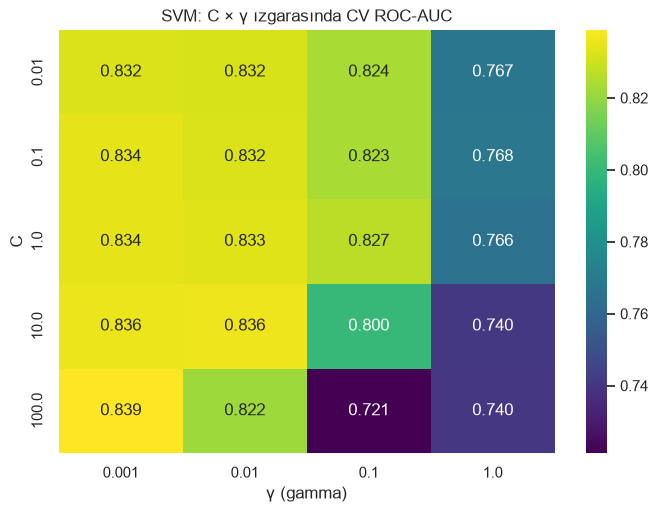

Destek vektörü sayısı (sınıf 0, sınıf 1): [146 148] → eğitim verisinin %51.0'i


In [19]:
s = pd.DataFrame(aramalar["SVM"].cv_results_)
tablo = s.pivot(index="param_model__C", columns="param_model__gamma", values="mean_test_score")
plt.figure(figsize=(8, 5.5))
sns.heatmap(tablo, annot=True, fmt=".3f", cmap="viridis")
plt.xlabel("γ (gamma)")
plt.ylabel("C")
plt.title("SVM: C × γ ızgarasında CV ROC-AUC")
plt.show()
print("Destek vektörü sayısı (sınıf 0, sınıf 1):", modeller["SVM"].named_steps["model"].n_support_,
      f"→ eğitim verisinin %{modeller['SVM'].named_steps['model'].n_support_.sum() / len(y_egitim) * 100:.1f}'i")

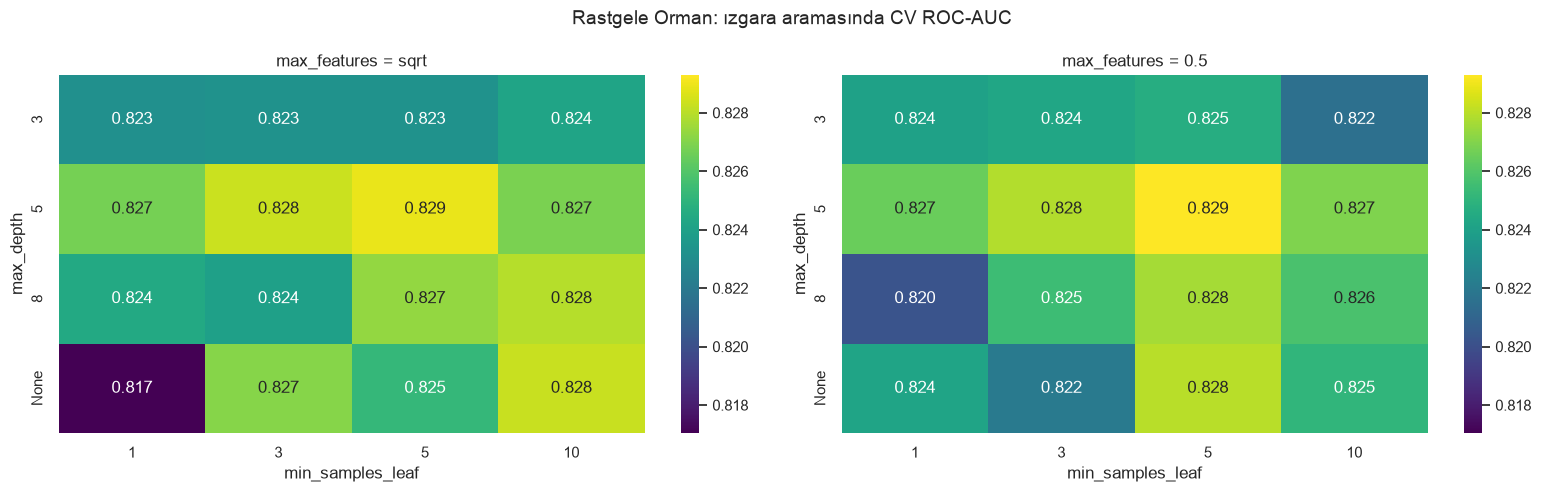

In [20]:
s = pd.DataFrame(aramalar["Rastgele Orman"].cv_results_)
s["max_depth"] = s["param_model__max_depth"].map(lambda v: "None" if v is None or v != v else str(int(v)))
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, mf in zip(axes, ["sqrt", 0.5]):
    alt = s[s["param_model__max_features"].astype(str) == str(mf)]
    t = alt.pivot(index="max_depth", columns="param_model__min_samples_leaf", values="mean_test_score")
    sns.heatmap(t.loc[["3", "5", "8", "None"]], annot=True, fmt=".3f", cmap="viridis", ax=ax, vmin=s["mean_test_score"].min(),
                vmax=s["mean_test_score"].max())
    ax.set_title(f"max_features = {mf}")
    ax.set_xlabel("min_samples_leaf")
fig.suptitle("Rastgele Orman: ızgara aramasında CV ROC-AUC", fontsize=14)
plt.tight_layout()
plt.show()

In [21]:
def hata_matrisi_ciz(ad):
    cm = confusion_matrix(y_test, tahminler[ad])
    tn, fp, fn, tp = cm.ravel()
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    ConfusionMatrixDisplay(cm, display_labels=SINIFLAR).plot(cmap="Blues", ax=axes[0], colorbar=False,
                                                             text_kw={"fontsize": 18})
    axes[0].set_title(f"{ad} — hata matrisi (sayı)")
    oran = confusion_matrix(y_test, tahminler[ad], normalize="true")
    et = np.array([[f"TN = {tn}\n%{oran[0, 0] * 100:.1f}", f"FP = {fp}\n%{oran[0, 1] * 100:.1f}"],
                   [f"FN = {fn}\n%{oran[1, 0] * 100:.1f}", f"TP = {tp}\n%{oran[1, 1] * 100:.1f}"]])
    sns.heatmap(oran, annot=et, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=axes[1],
                xticklabels=SINIFLAR, yticklabels=SINIFLAR, annot_kws={"fontsize": 14})
    axes[1].set_title(f"{ad} — gerçek sınıfa göre oranlar")
    for ax in axes:
        ax.set_xlabel("Tahmin edilen sınıf")
        ax.set_ylabel("Gerçek sınıf")
    plt.tight_layout()
    plt.show()
    n = cm.sum()
    return pd.Series({"TN": tn, "FP": fp, "FN": fn, "TP": tp,
                      "Doğruluk": (tp + tn) / n, "Duyarlılık (TPR)": tp / (tp + fn), "Özgüllük (TNR)": tn / (tn + fp),
                      "Kesinlik (PPV)": tp / (tp + fp), "NPV": tn / (tn + fn),
                      "FPR": fp / (fp + tn), "FNR": fn / (fn + tp)}, name=ad)

hm = {}

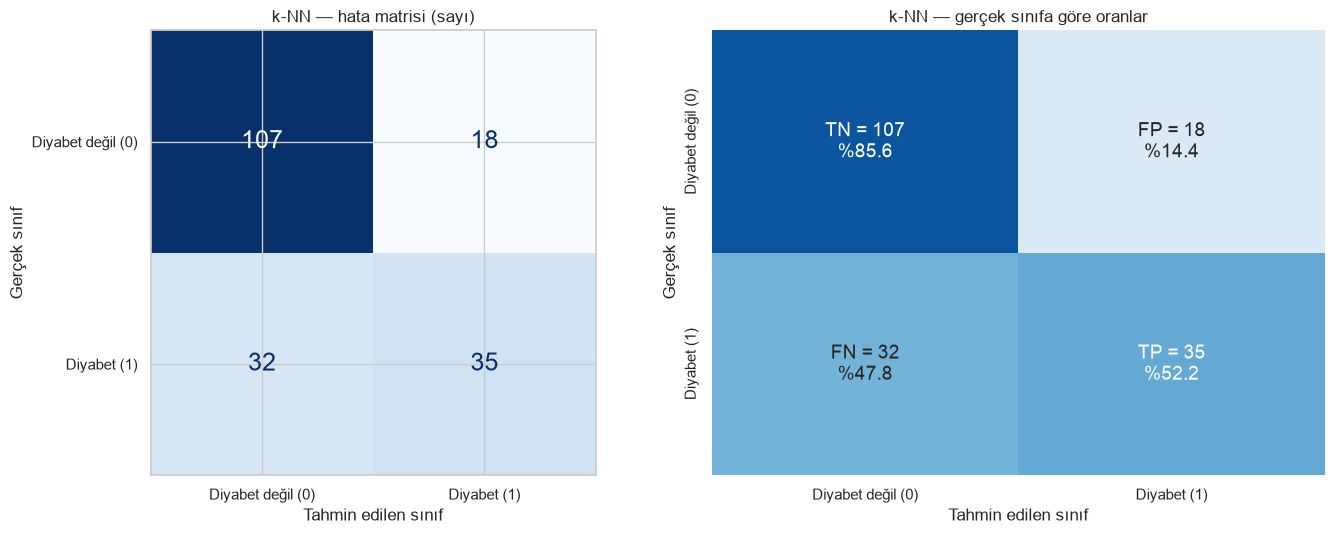

,k-NN
TN,107.0000
FP,18.0000
FN,32.0000
TP,35.0000
Doğruluk,0.7396
Duyarlılık (TPR),0.5224
Özgüllük (TNR),0.8560
Kesinlik (PPV),0.6604
NPV,0.7698
FPR,0.1440


In [22]:
hm["k-NN"] = hata_matrisi_ciz("k-NN")
hm["k-NN"].to_frame()

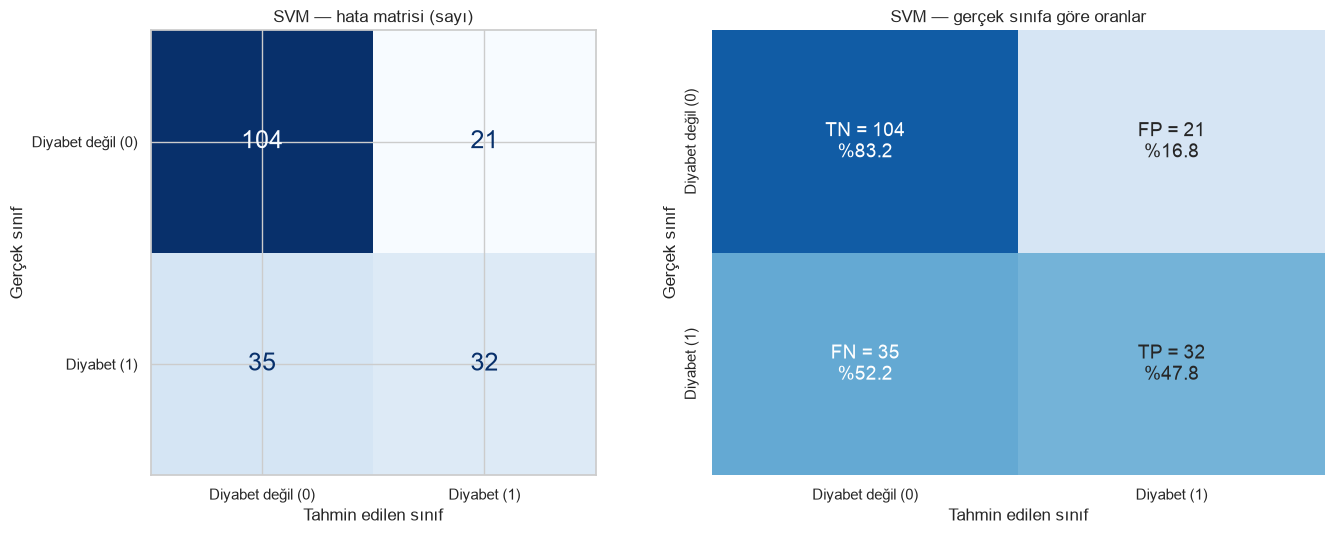

,SVM
TN,104.0000
FP,21.0000
FN,35.0000
TP,32.0000
Doğruluk,0.7083
Duyarlılık (TPR),0.4776
Özgüllük (TNR),0.8320
Kesinlik (PPV),0.6038
NPV,0.7482
FPR,0.1680


In [23]:
hm["SVM"] = hata_matrisi_ciz("SVM")
hm["SVM"].to_frame()

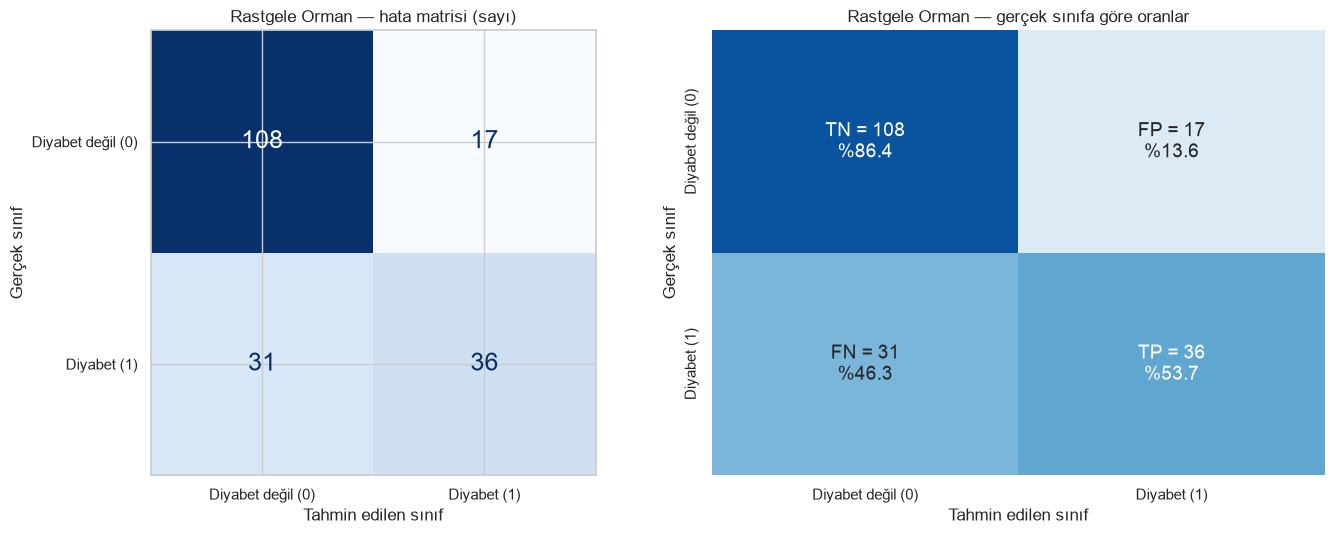

,Rastgele Orman
TN,108.0000
FP,17.0000
FN,31.0000
TP,36.0000
Doğruluk,0.7500
Duyarlılık (TPR),0.5373
Özgüllük (TNR),0.8640
Kesinlik (PPV),0.6792
NPV,0.7770
FPR,0.1360


In [24]:
hm["Rastgele Orman"] = hata_matrisi_ciz("Rastgele Orman")
hm["Rastgele Orman"].to_frame()

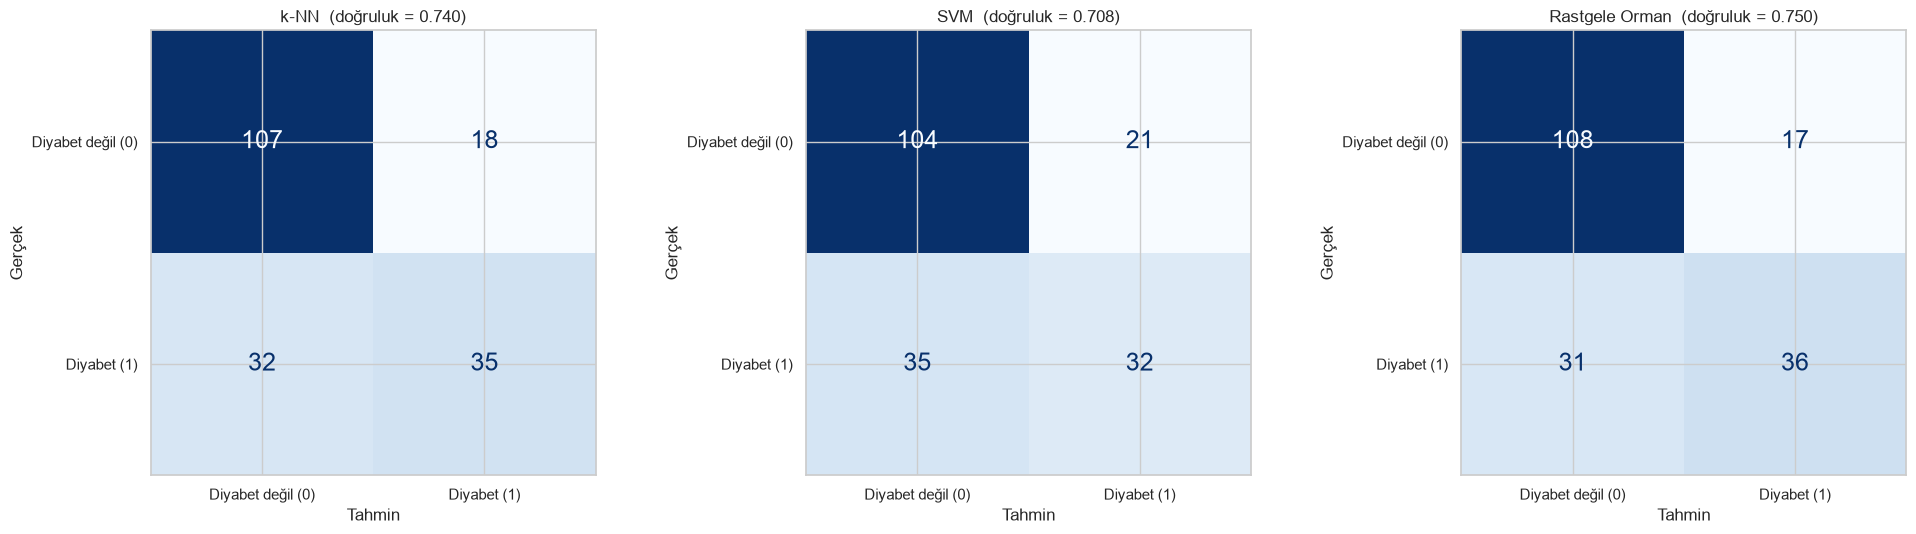

,TN,FP,FN,TP,Doğruluk,Duyarlılık (TPR),Özgüllük (TNR),Kesinlik (PPV),NPV,FPR,FNR
k-NN,107.0000,18.0000,32.0000,35.0000,0.7396,0.5224,0.8560,0.6604,0.7698,0.1440,0.4776
SVM,104.0000,21.0000,35.0000,32.0000,0.7083,0.4776,0.8320,0.6038,0.7482,0.1680,0.5224
Rastgele Orman,108.0000,17.0000,31.0000,36.0000,0.7500,0.5373,0.8640,0.6792,0.7770,0.1360,0.4627


In [25]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, ad in zip(axes, modeller):
    ConfusionMatrixDisplay(confusion_matrix(y_test, tahminler[ad]), display_labels=SINIFLAR) \
        .plot(cmap="Blues", ax=ax, colorbar=False, text_kw={"fontsize": 18})
    ax.set_title(f"{ad}  (doğruluk = {accuracy_score(y_test, tahminler[ad]):.3f})")
    ax.set_xlabel("Tahmin")
    ax.set_ylabel("Gerçek")
plt.tight_layout()
plt.show()
pd.DataFrame(hm).T

In [26]:
hatali = pd.DataFrame({ad: tahminler[ad] != y_test.values for ad in modeller}, index=y_test.index)
ortusme = hatali.sum(axis=1).value_counts().sort_index()
ortusme.index = [f"{i} yöntem hatalı" for i in ortusme.index]
display(ortusme.to_frame("Gözlem sayısı"))
print("Her üç yöntemin de yanlış sınıflandırdığı gözlemlerin gerçek sınıf dağılımı:")
y_test[hatali.all(axis=1)].map({0: SINIFLAR[0], 1: SINIFLAR[1]}).value_counts()

,Gözlem sayısı
0 yöntem hatalı,130
1 yöntem hatalı,11
2 yöntem hatalı,10
3 yöntem hatalı,41


Her üç yöntemin de yanlış sınıflandırdığı gözlemlerin gerçek sınıf dağılımı:


Sonuc
Diyabet (1)          27
Diyabet değil (0)    14
Name: count, dtype: int64

In [27]:
def rapor(ad):
    print(f"SINIFLANDIRMA RAPORU — {ad} (test verisi, n = {len(y_test)})")
    print("=" * 64)
    print(classification_report(y_test, tahminler[ad], target_names=SINIFLAR, digits=4))
    return pd.Series({
        "Doğruluk": accuracy_score(y_test, tahminler[ad]),
        "Dengeli doğruluk": balanced_accuracy_score(y_test, tahminler[ad]),
        "Kesinlik (diyabet)": precision_score(y_test, tahminler[ad]),
        "Duyarlılık (diyabet)": recall_score(y_test, tahminler[ad]),
        "F1 (diyabet)": f1_score(y_test, tahminler[ad]),
        "Makro F1": f1_score(y_test, tahminler[ad], average="macro"),
        "ROC-AUC": roc_auc_score(y_test, skorlar[ad]),
        "PR-AUC (AP)": average_precision_score(y_test, skorlar[ad]),
        "MCC": matthews_corrcoef(y_test, tahminler[ad]),
        "Cohen Kappa": cohen_kappa_score(y_test, tahminler[ad]),
    }, name=ad)

rp = {}

In [28]:
rp["k-NN"] = rapor("k-NN")
rp["k-NN"].to_frame("Değer")

SINIFLANDIRMA RAPORU — k-NN (test verisi, n = 192)
                   precision    recall  f1-score   support

Diyabet değil (0)     0.7698    0.8560    0.8106       125
      Diyabet (1)     0.6604    0.5224    0.5833        67

         accuracy                         0.7396       192
        macro avg     0.7151    0.6892    0.6970       192
     weighted avg     0.7316    0.7396    0.7313       192



,Değer
Doğruluk,0.7396
Dengeli doğruluk,0.6892
Kesinlik (diyabet),0.6604
Duyarlılık (diyabet),0.5224
F1 (diyabet),0.5833
Makro F1,0.6970
ROC-AUC,0.8154
PR-AUC (AP),0.7027
MCC,0.4034
Cohen Kappa,0.3977


In [29]:
rp["SVM"] = rapor("SVM")
rp["SVM"].to_frame("Değer")

SINIFLANDIRMA RAPORU — SVM (test verisi, n = 192)
                   precision    recall  f1-score   support

Diyabet değil (0)     0.7482    0.8320    0.7879       125
      Diyabet (1)     0.6038    0.4776    0.5333        67

         accuracy                         0.7083       192
        macro avg     0.6760    0.6548    0.6606       192
     weighted avg     0.6978    0.7083    0.6991       192



,Değer
Doğruluk,0.7083
Dengeli doğruluk,0.6548
Kesinlik (diyabet),0.6038
Duyarlılık (diyabet),0.4776
F1 (diyabet),0.5333
Makro F1,0.6606
ROC-AUC,0.8241
PR-AUC (AP),0.7069
MCC,0.3301
Cohen Kappa,0.3254


In [30]:
rp["Rastgele Orman"] = rapor("Rastgele Orman")
rp["Rastgele Orman"].to_frame("Değer")

SINIFLANDIRMA RAPORU — Rastgele Orman (test verisi, n = 192)
                   precision    recall  f1-score   support

Diyabet değil (0)     0.7770    0.8640    0.8182       125
      Diyabet (1)     0.6792    0.5373    0.6000        67

         accuracy                         0.7500       192
        macro avg     0.7281    0.7007    0.7091       192
     weighted avg     0.7429    0.7500    0.7420       192



,Değer
Doğruluk,0.7500
Dengeli doğruluk,0.7007
Kesinlik (diyabet),0.6792
Duyarlılık (diyabet),0.5373
F1 (diyabet),0.6000
Makro F1,0.7091
ROC-AUC,0.8205
PR-AUC (AP),0.6983
MCC,0.4279
Cohen Kappa,0.4218


In [31]:
def ortak_grafikler(ad):
    s, renk = skorlar[ad], RENK_YONTEM[ad]
    esik0 = 0.0 if ad == "SVM" else 0.5
    fig, axes = plt.subplots(2, 2, figsize=(17, 12))

    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0, 0].plot(fpr, tpr, color=renk, linewidth=2.5, label=f"AUC = {roc_auc_score(y_test, s):.3f}")
    axes[0, 0].fill_between(fpr, tpr, alpha=0.1, color=renk)
    axes[0, 0].plot([0, 1], [0, 1], "k--", label="Rastgele")
    tn, fp, fn, tp = confusion_matrix(y_test, tahminler[ad]).ravel()
    axes[0, 0].scatter(fp / (fp + tn), tp / (tp + fn), s=150, c="red", zorder=5, label="Varsayılan eşik")
    axes[0, 0].set_xlabel("Yanlış Pozitif Oranı")
    axes[0, 0].set_ylabel("Doğru Pozitif Oranı (Duyarlılık)")
    axes[0, 0].set_title(f"{ad} — ROC eğrisi")
    axes[0, 0].legend(loc="lower right")

    kes, duy, _ = precision_recall_curve(y_test, s)
    axes[0, 1].plot(duy, kes, color=renk, linewidth=2.5, label=f"AP = {average_precision_score(y_test, s):.3f}")
    axes[0, 1].axhline(y_test.mean(), color="black", linestyle="--", label=f"Rastgele ({y_test.mean():.3f})")
    axes[0, 1].scatter(tp / (tp + fn), tp / (tp + fp), s=150, c="red", zorder=5, label="Varsayılan eşik")
    axes[0, 1].set_xlabel("Duyarlılık")
    axes[0, 1].set_ylabel("Kesinlik")
    axes[0, 1].set_ylim(0, 1.05)
    axes[0, 1].set_title(f"{ad} — Kesinlik–Duyarlılık eğrisi")
    axes[0, 1].legend(loc="lower left")

    for c in [0, 1]:
        sns.histplot(s[y_test.values == c], bins=25, color=RENK[c], alpha=0.55, stat="density", kde=True,
                     label=SINIFLAR[c], ax=axes[1, 0])
    axes[1, 0].axvline(esik0, color="black", linestyle="--", label=f"Eşik = {esik0}")
    axes[1, 0].set_xlabel("Karar fonksiyonu değeri" if ad == "SVM" else "Tahmin edilen P(diyabet)")
    axes[1, 0].set_title(f"{ad} — sınıflara göre skor dağılımı")
    axes[1, 0].legend()

    esikler = np.quantile(s, np.linspace(0.02, 0.98, 97))
    axes[1, 1].plot(esikler, [recall_score(y_test, s >= e) for e in esikler], label="Duyarlılık", linewidth=2)
    axes[1, 1].plot(esikler, [precision_score(y_test, s >= e, zero_division=1) for e in esikler], label="Kesinlik", linewidth=2)
    axes[1, 1].plot(esikler, [f1_score(y_test, s >= e) for e in esikler], label="F1", linewidth=2)
    axes[1, 1].plot(esikler, [recall_score(y_test, s >= e, pos_label=0) for e in esikler], label="Özgüllük", linewidth=2, linestyle=":")
    axes[1, 1].axvline(esik0, color="black", linestyle="--")
    axes[1, 1].set_xlabel("Karar eşiği")
    axes[1, 1].set_title(f"{ad} — karar eşiğine göre ölçütler")
    axes[1, 1].legend(loc="center left")
    plt.tight_layout()
    plt.show()

def ogrenme_egrisi(ad):
    boyut, egt, dog = learning_curve(modeller[ad], X_egitim, y_egitim, cv=cv, scoring="roc_auc",
                                     train_sizes=np.linspace(0.15, 1.0, 8), n_jobs=-1)
    fig, ax = plt.subplots(figsize=(9, 5))
    for sk, et, rk in [(egt, "Eğitim", "tab:blue"), (dog, "Doğrulama (CV)", "tab:orange")]:
        ax.plot(boyut, sk.mean(axis=1), "o-", color=rk, label=et)
        ax.fill_between(boyut, sk.mean(axis=1) - sk.std(axis=1), sk.mean(axis=1) + sk.std(axis=1), color=rk, alpha=0.15)
    ax.set_xlabel("Eğitim örneği sayısı")
    ax.set_ylabel("ROC-AUC")
    ax.set_ylim(0.6, 1.01)
    ax.set_title(f"{ad} — öğrenme eğrisi")
    ax.legend(loc="lower right")
    plt.show()
    return pd.Series({"Eğitim AUC (tam veri)": egt[-1].mean(), "CV AUC (tam veri)": dog[-1].mean(),
                      "Fark": egt[-1].mean() - dog[-1].mean()}, name=ad)

IKI = ["Glukoz", "VKI"]
X2_egitim = SimpleImputer(strategy="median").fit(X_egitim[IKI])
A_egitim, A_test = X2_egitim.transform(X_egitim[IKI]), X2_egitim.transform(X_test[IKI])
xx, yy = np.meshgrid(np.linspace(A_egitim[:, 0].min() - 5, A_egitim[:, 0].max() + 5, 300),
                     np.linspace(A_egitim[:, 1].min() - 2, A_egitim[:, 1].max() + 2, 300))

def karar_bolgesi(ad, ax):
    pipe = YONTEMLER[ad]["pipeline"].set_params(**aramalar[ad].best_params_)
    pipe = pipe.fit(pd.DataFrame(A_egitim, columns=IKI), y_egitim)
    zz = skor(pipe, pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=IKI)).reshape(xx.shape)
    esik0 = 0.0 if ad == "SVM" else 0.5
    if ad == "SVM":
        cf = ax.contourf(xx, yy, zz, levels=np.linspace(-2.5, 2.5, 21), cmap="RdYlGn_r", alpha=0.45, extend="both")
    else:
        cf = ax.contourf(xx, yy, zz, levels=np.linspace(0, 1, 21), cmap="RdYlGn_r", alpha=0.45)
    ax.contour(xx, yy, zz, levels=[esik0], colors="black", linewidths=2.2)
    for c in [0, 1]:
        m = y_test.values == c
        ax.scatter(A_test[m, 0], A_test[m, 1], c=RENK[c], s=35, edgecolor="black", linewidth=0.5, label=f"Test — {SINIFLAR[c]}")
    tah = pipe.predict(pd.DataFrame(A_test, columns=IKI))
    ax.set_xlabel("Glukoz")
    ax.set_ylabel("VKİ")
    ax.set_title(f"{ad} — karar sınırı (Glukoz × VKİ)\n2 özellikli model test doğruluğu = {accuracy_score(y_test, tah):.3f}")
    ax.legend(loc="upper left", fontsize=9)
    return cf

ogr = {}

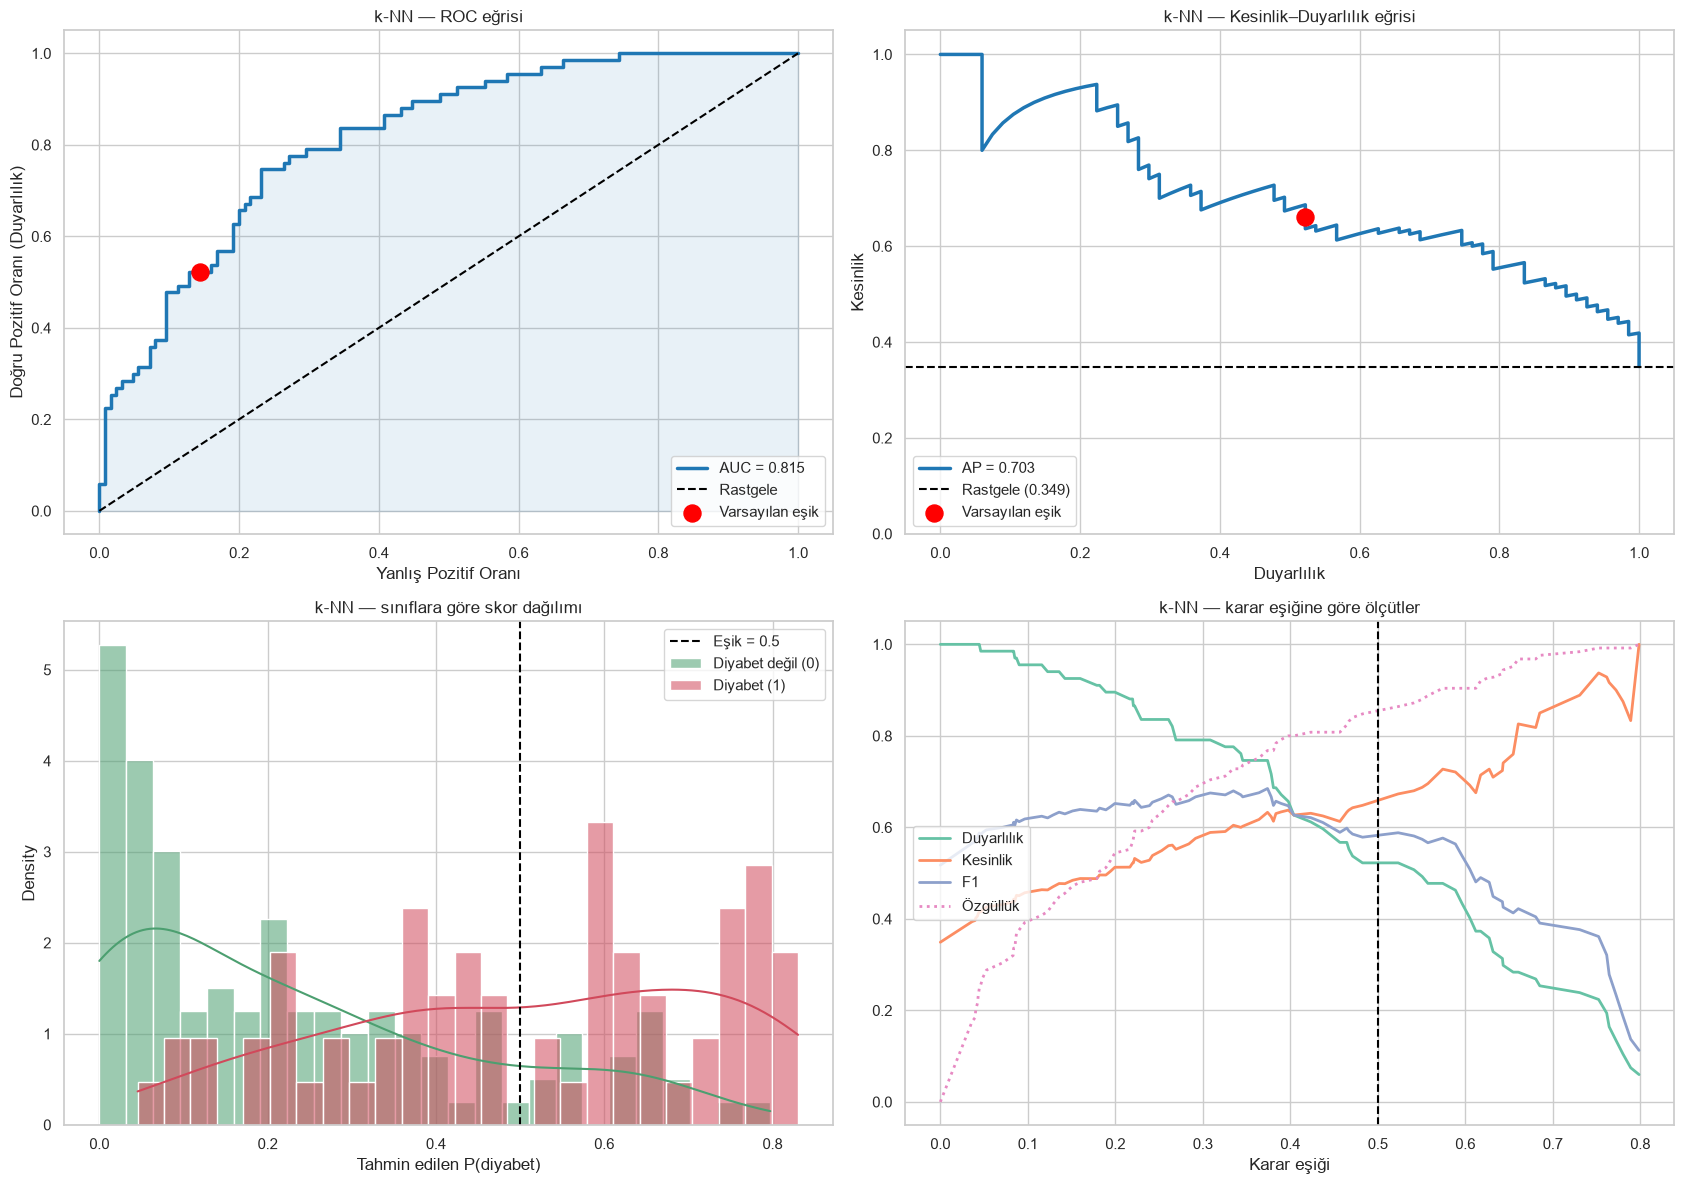

In [32]:
ortak_grafikler("k-NN")

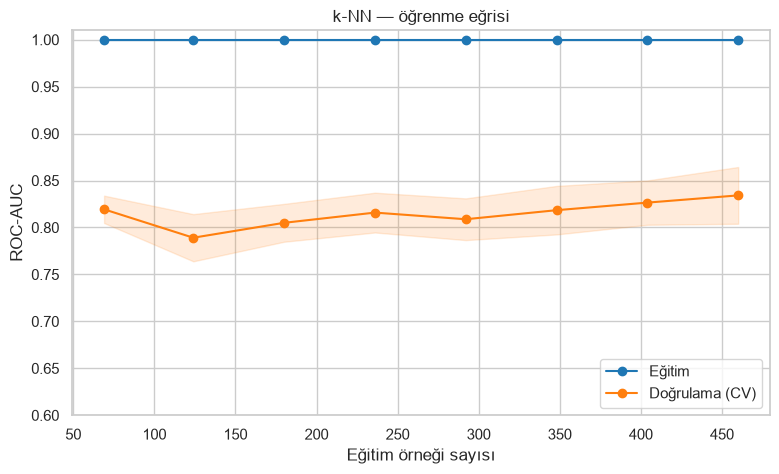

In [33]:
ogr["k-NN"] = ogrenme_egrisi("k-NN")

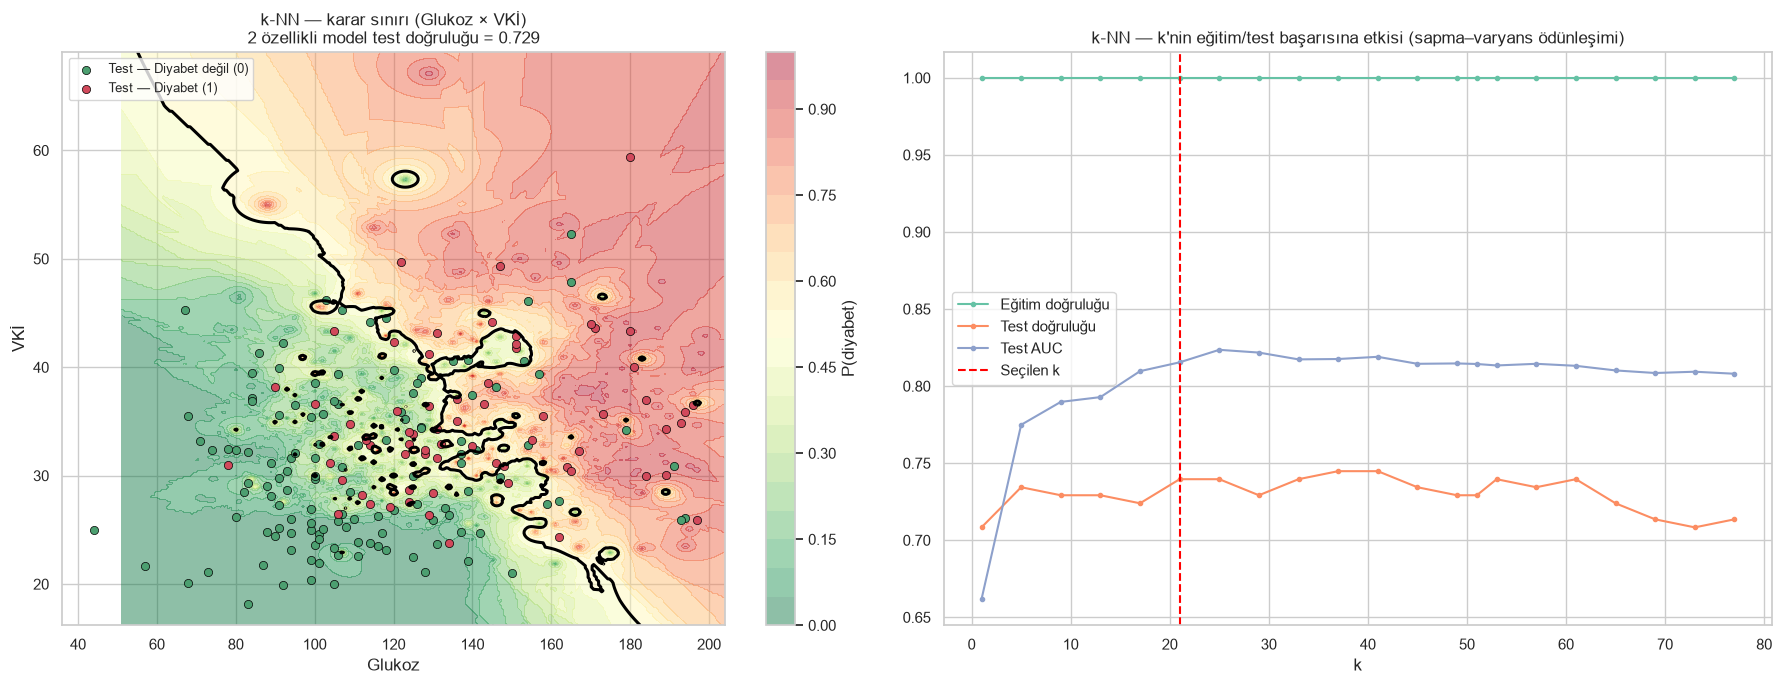

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
cf = karar_bolgesi("k-NN", axes[0])
plt.colorbar(cf, ax=axes[0], label="P(diyabet)")
k_deger = sorted({1, aramalar["k-NN"].best_params_["model__n_neighbors"], 51} | set(range(1, 80, 4)))
sonuc_k = []
for k in k_deger:
    m = YONTEMLER["k-NN"]["pipeline"].set_params(**{**aramalar["k-NN"].best_params_, "model__n_neighbors": k}).fit(X_egitim, y_egitim)
    sonuc_k.append({"k": k, "Eğitim doğruluğu": accuracy_score(y_egitim, m.predict(X_egitim)),
                    "Test doğruluğu": accuracy_score(y_test, m.predict(X_test)),
                    "Test AUC": roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])})
sonuc_k = pd.DataFrame(sonuc_k).set_index("k")
sonuc_k.plot(ax=axes[1], marker="o", markersize=3)
axes[1].axvline(aramalar["k-NN"].best_params_["model__n_neighbors"], color="red", linestyle="--", label="Seçilen k")
axes[1].set_title("k-NN — k'nin eğitim/test başarısına etkisi (sapma–varyans ödünleşimi)")
axes[1].legend()
plt.tight_layout()
plt.show()

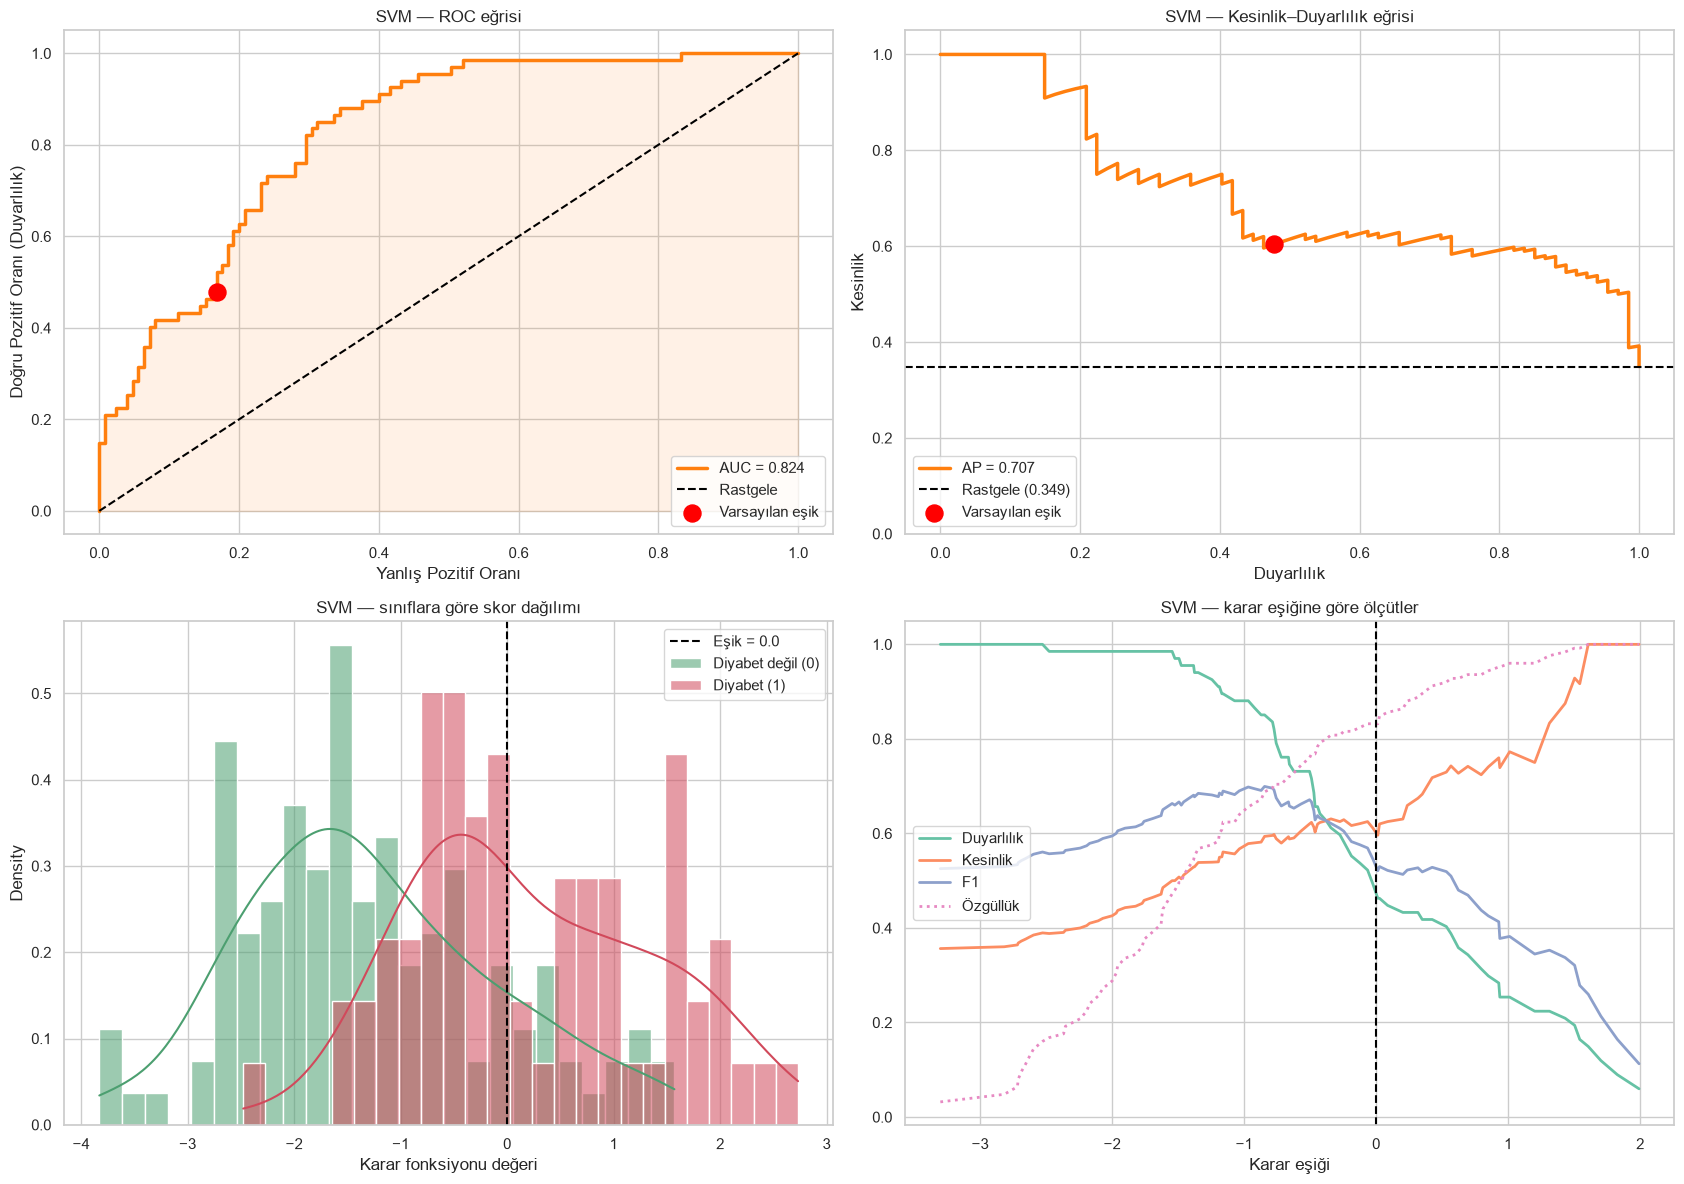

In [35]:
ortak_grafikler("SVM")

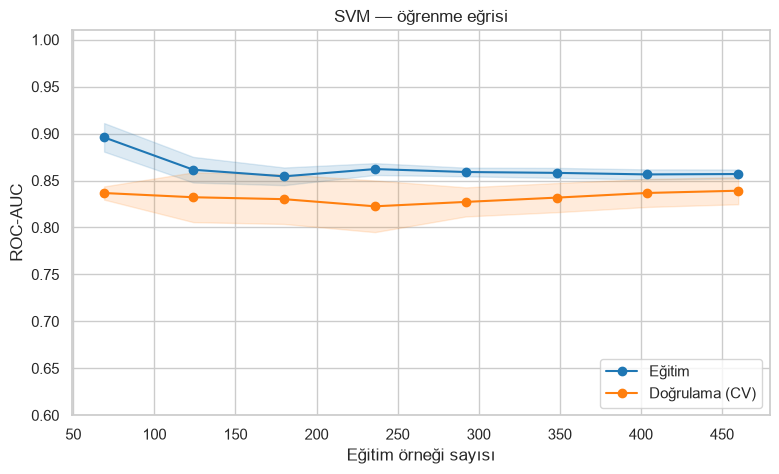

In [36]:
ogr["SVM"] = ogrenme_egrisi("SVM")

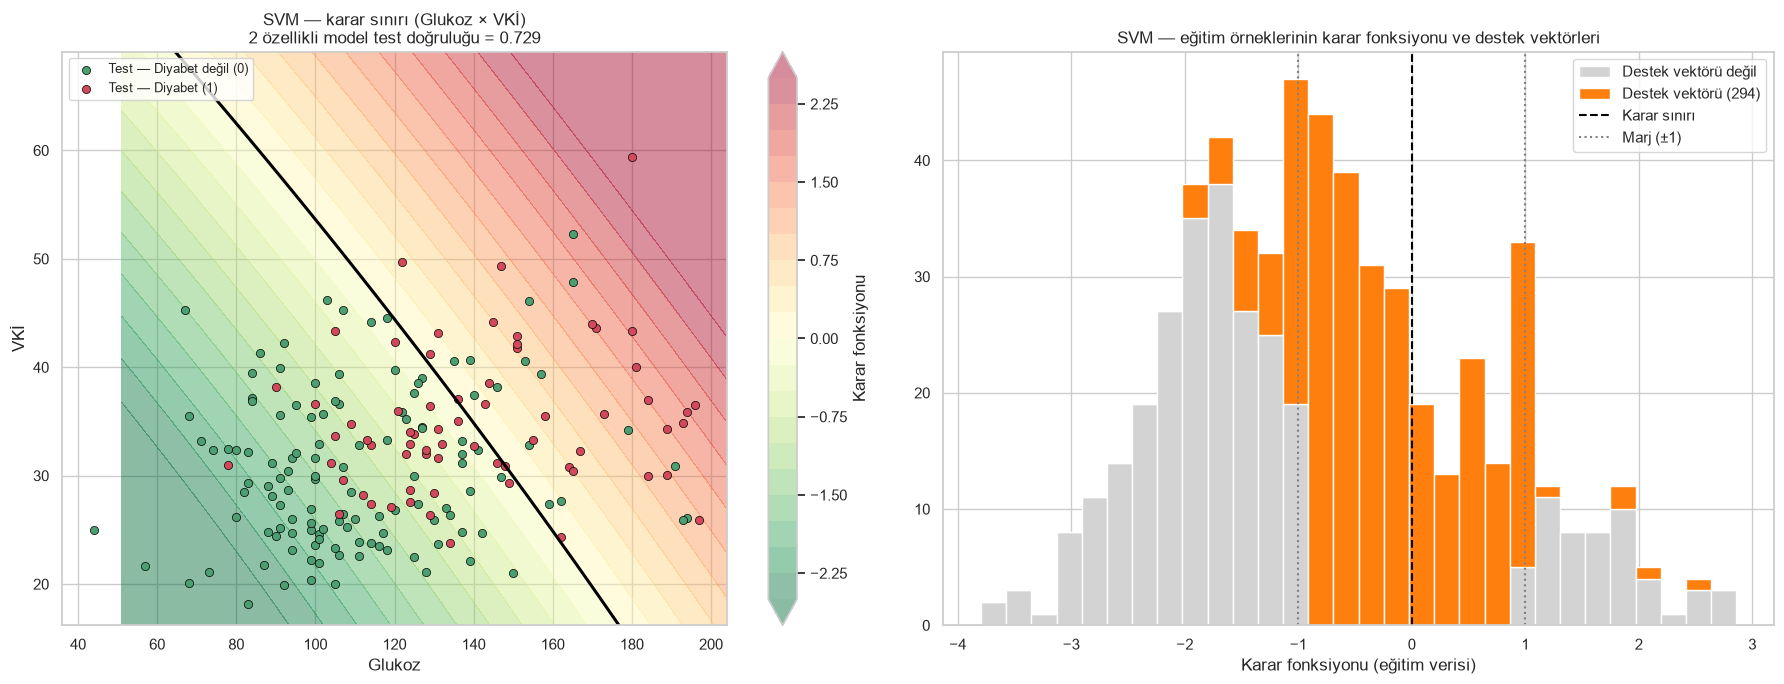

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
cf = karar_bolgesi("SVM", axes[0])
plt.colorbar(cf, ax=axes[0], label="Karar fonksiyonu")
svm_m = modeller["SVM"]
dv = svm_m.decision_function(X_egitim)
sv = svm_m.named_steps["model"].support_
axes[1].hist([dv[np.setdiff1d(np.arange(len(dv)), sv)], dv[sv]], bins=30, stacked=True,
             label=["Destek vektörü değil", f"Destek vektörü ({len(sv)})"], color=["lightgray", "tab:orange"])
axes[1].axvline(0, color="black", linestyle="--", label="Karar sınırı")
axes[1].axvline(-1, color="gray", linestyle=":")
axes[1].axvline(1, color="gray", linestyle=":", label="Marj (±1)")
axes[1].set_xlabel("Karar fonksiyonu (eğitim verisi)")
axes[1].set_title("SVM — eğitim örneklerinin karar fonksiyonu ve destek vektörleri")
axes[1].legend()
plt.tight_layout()
plt.show()

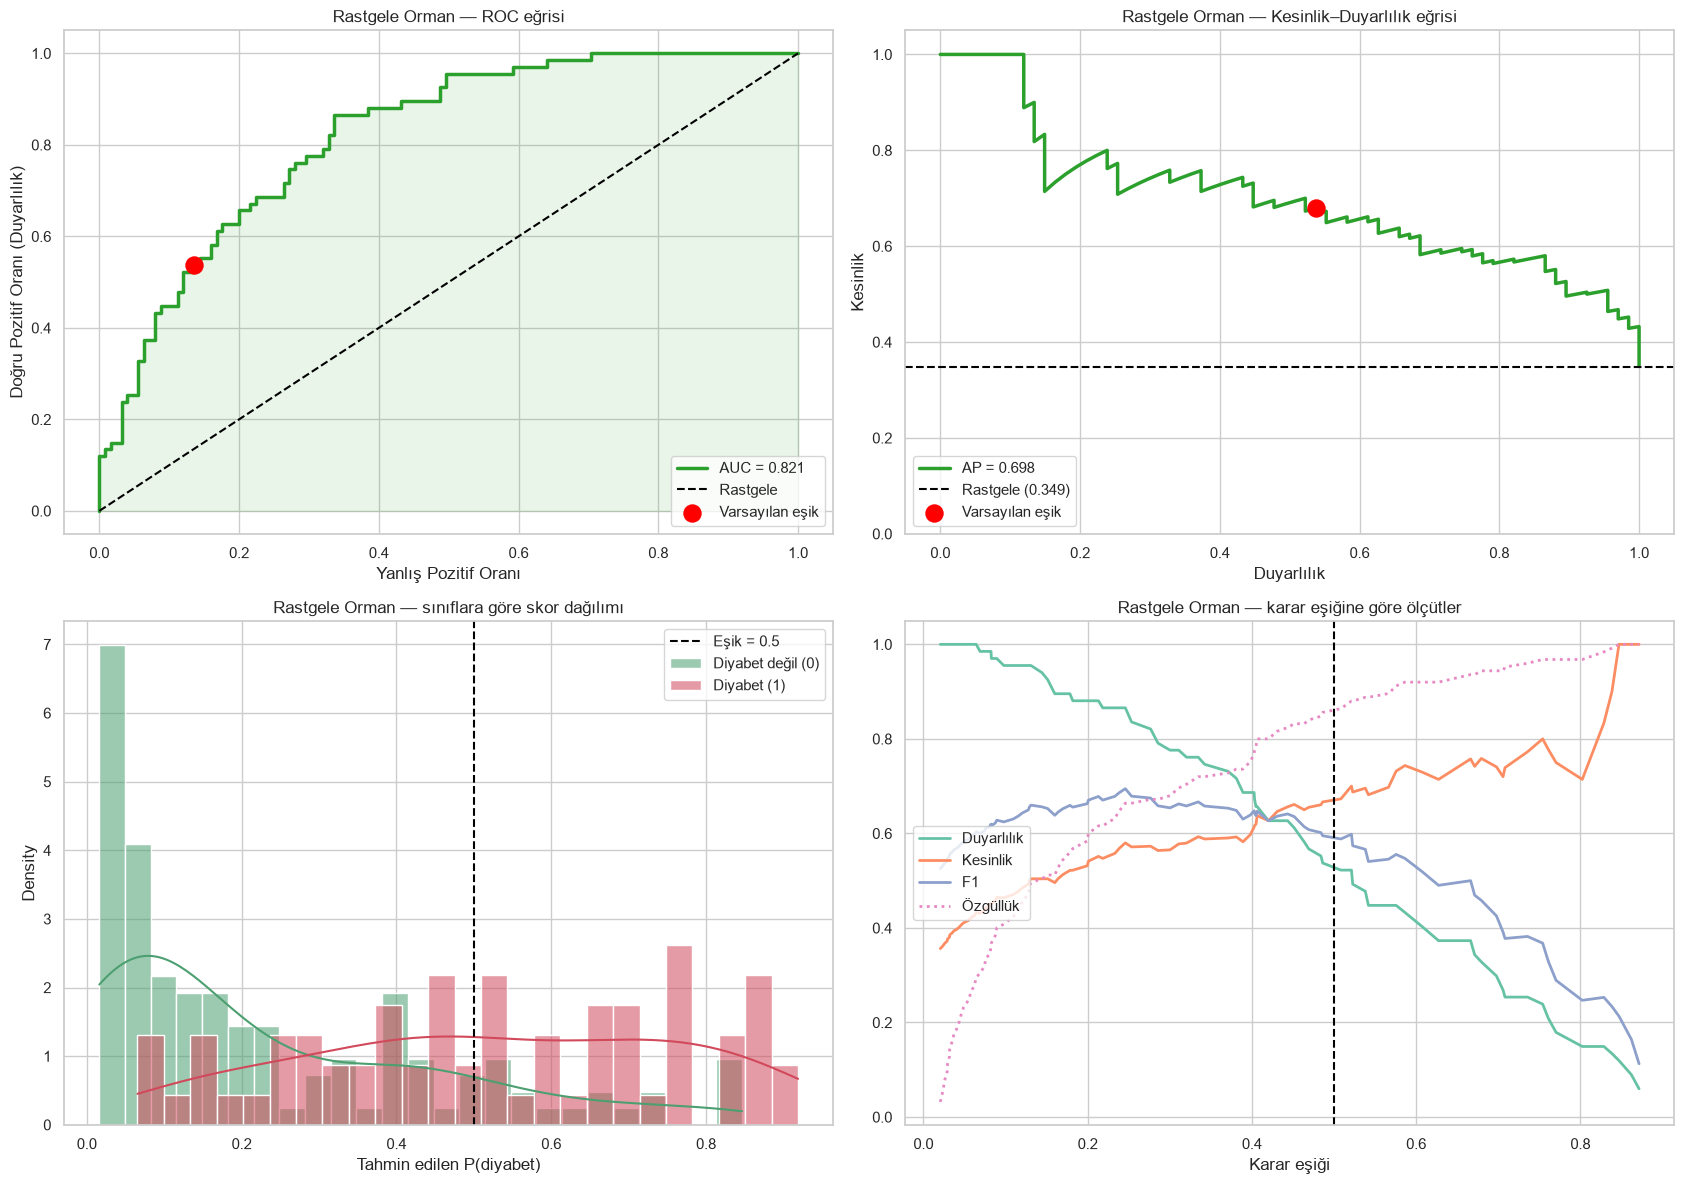

In [38]:
ortak_grafikler("Rastgele Orman")

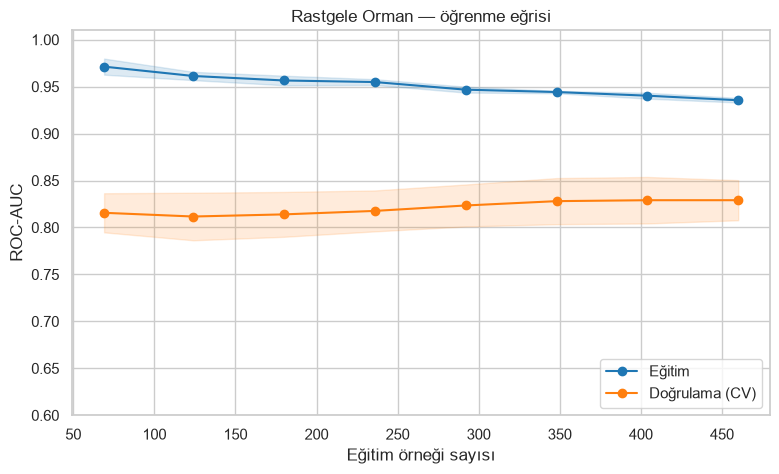

In [39]:
ogr["Rastgele Orman"] = ogrenme_egrisi("Rastgele Orman")

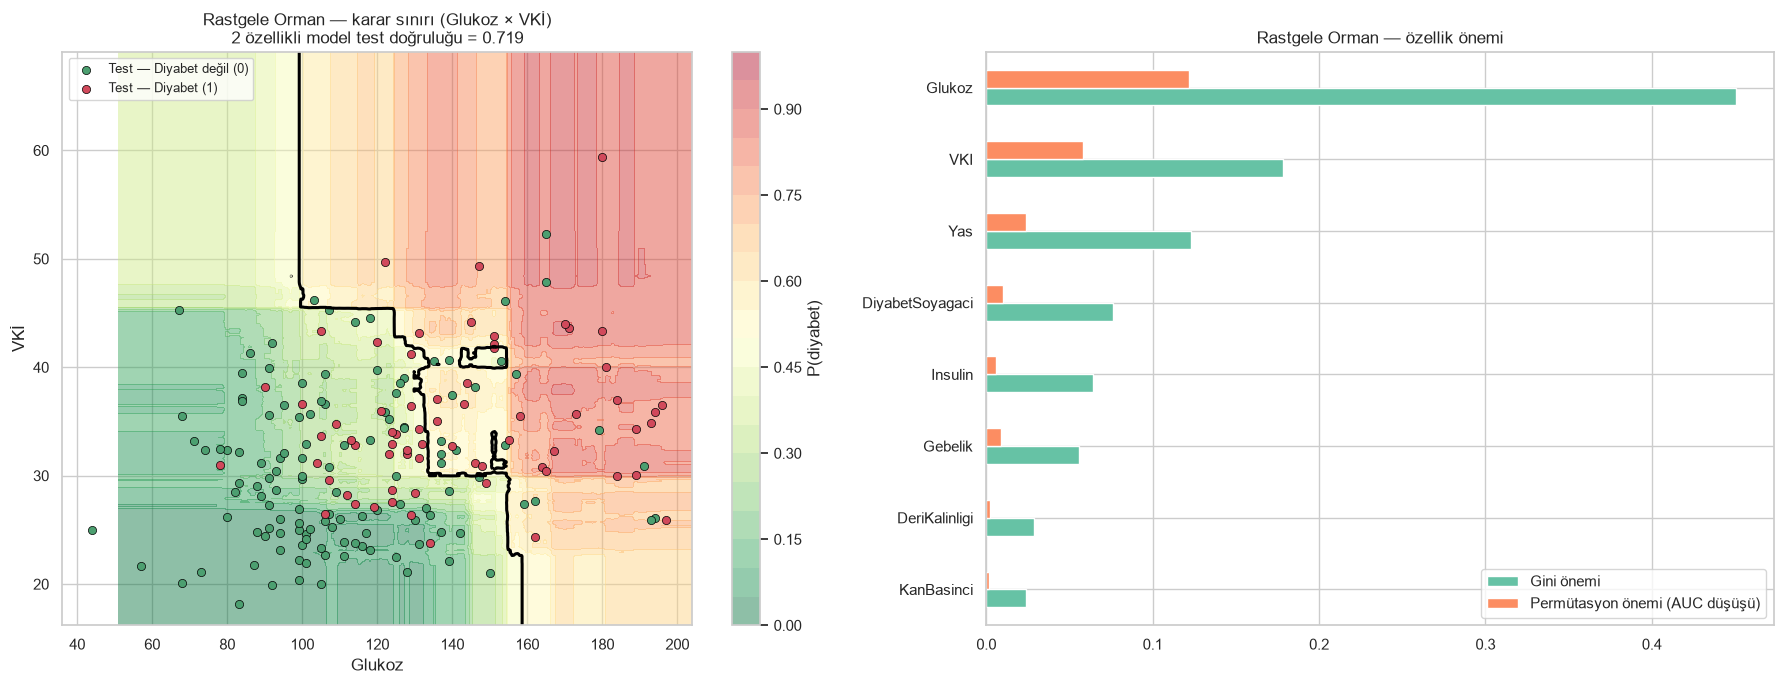

,Gini önemi,Permütasyon önemi (AUC düşüşü)
Glukoz,0.4509,0.1217
VKI,0.1782,0.0582
Yas,0.1231,0.0239
DiyabetSoyagaci,0.0760,0.0099
Insulin,0.0639,0.0058
Gebelik,0.0555,0.0086
DeriKalinligi,0.0289,0.0024
KanBasinci,0.0236,0.0017


In [40]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
cf = karar_bolgesi("Rastgele Orman", axes[0])
plt.colorbar(cf, ax=axes[0], label="P(diyabet)")
rf_m = modeller["Rastgele Orman"]
gini = pd.Series(rf_m.named_steps["model"].feature_importances_, index=OZELLIKLER)
perm = permutation_importance(rf_m, X_test, y_test, n_repeats=30, random_state=42, scoring="roc_auc")
onem = pd.DataFrame({"Gini önemi": gini, "Permütasyon önemi (AUC düşüşü)": perm.importances_mean}).sort_values("Gini önemi")
onem.plot.barh(ax=axes[1])
axes[1].set_title("Rastgele Orman — özellik önemi")
plt.tight_layout()
plt.show()
onem.sort_values("Gini önemi", ascending=False)

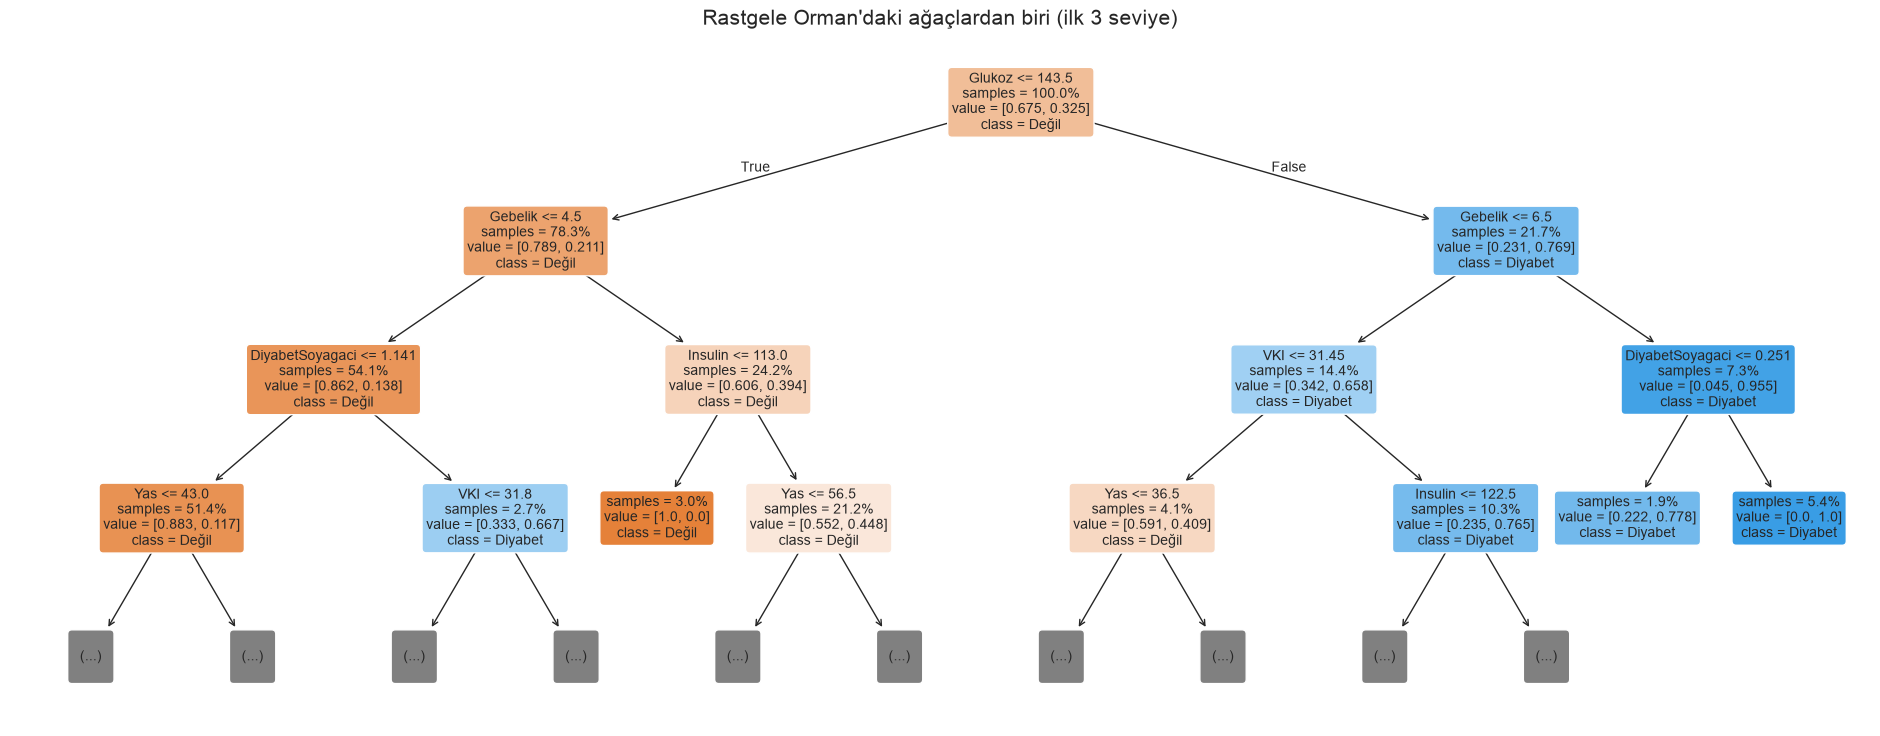

In [41]:
fig, ax = plt.subplots(figsize=(24, 9))
plot_tree(rf_m.named_steps["model"].estimators_[0], feature_names=OZELLIKLER, class_names=["Değil", "Diyabet"],
          filled=True, rounded=True, max_depth=3, fontsize=10, impurity=False, proportion=True, ax=ax)
ax.set_title("Rastgele Orman'daki ağaçlardan biri (ilk 3 seviye)", fontsize=15)
plt.show()

In [42]:
karsilastirma = pd.DataFrame(rp).T
karsilastirma["Eğitim+arama süresi (sn)"] = pd.Series(sureler)
tahmin_suresi = {}
for ad, m in modeller.items():
    t0 = time.perf_counter()
    for _ in range(20):
        m.predict(X_test)
    tahmin_suresi[ad] = (time.perf_counter() - t0) / 20 * 1000
karsilastirma["Tahmin süresi (ms / 192 gözlem)"] = pd.Series(tahmin_suresi)
olcut = ["Doğruluk", "Dengeli doğruluk", "Kesinlik (diyabet)", "Duyarlılık (diyabet)", "F1 (diyabet)",
         "Makro F1", "ROC-AUC", "PR-AUC (AP)", "MCC", "Cohen Kappa"]
karsilastirma.style.highlight_max(subset=olcut, color="lightgreen") \
             .highlight_min(subset=["Eğitim+arama süresi (sn)", "Tahmin süresi (ms / 192 gözlem)"], color="lightgreen") \
             .format("{:.4f}")

,Doğruluk,Dengeli doğruluk,Kesinlik (diyabet),Duyarlılık (diyabet),F1 (diyabet),Makro F1,ROC-AUC,PR-AUC (AP),MCC,Cohen Kappa,Eğitim+arama süresi (sn),Tahmin süresi (ms / 192 gözlem)
k-NN,0.7396,0.6892,0.6604,0.5224,0.5833,0.6970,0.8154,0.7027,0.4034,0.3977,3.9265,1.9063
SVM,0.7083,0.6548,0.6038,0.4776,0.5333,0.6606,0.8241,0.7069,0.3301,0.3254,0.3454,1.9362
Rastgele Orman,0.7500,0.7007,0.6792,0.5373,0.6000,0.7091,0.8205,0.6983,0.4279,0.4218,12.9128,12.5432


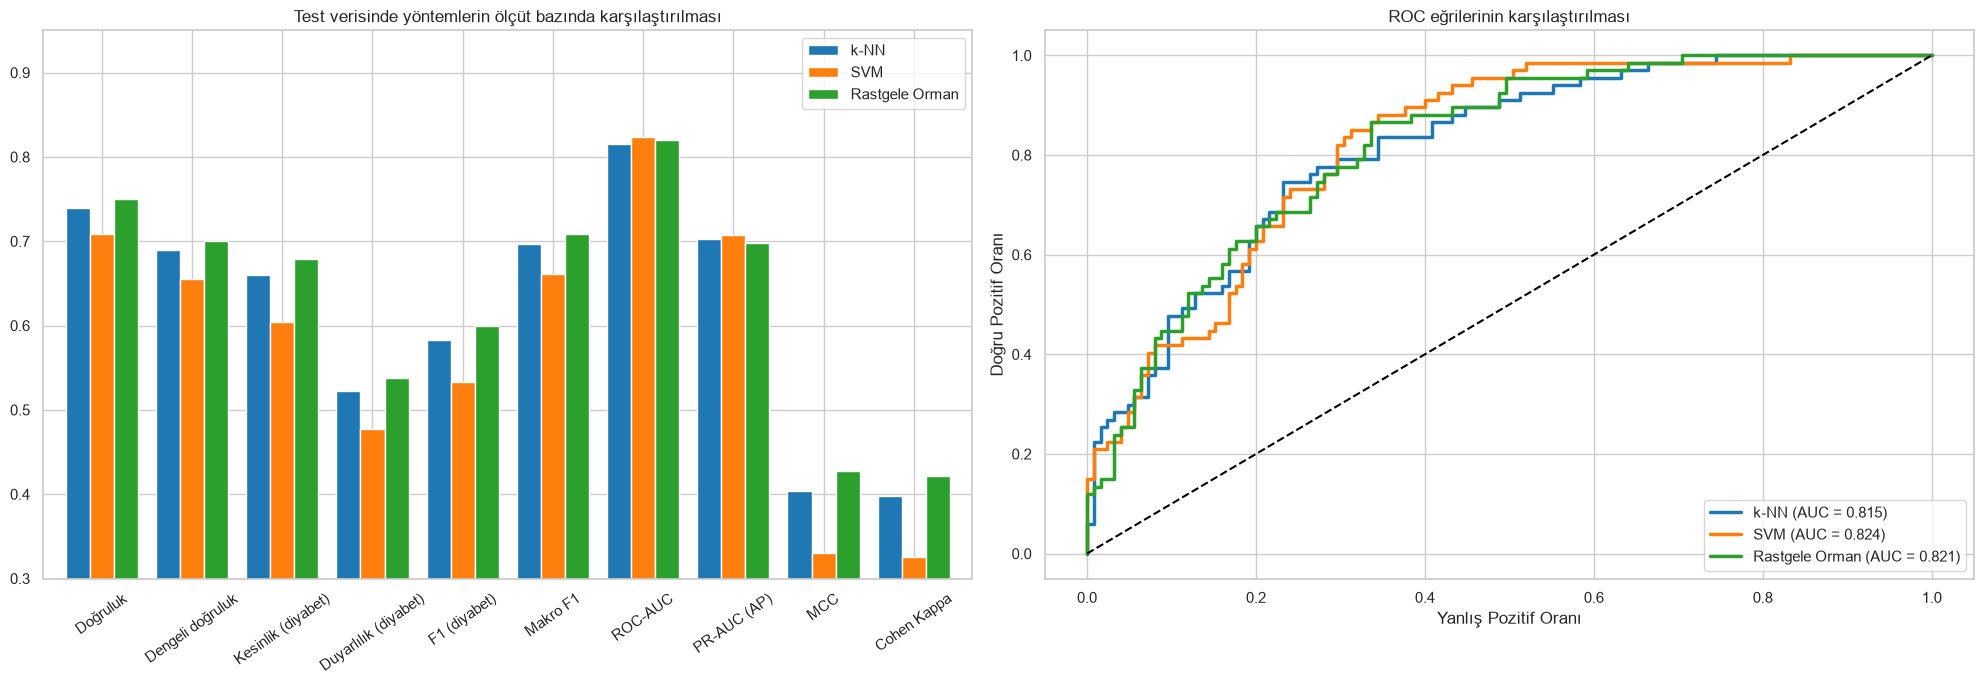

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(20, 7))
karsilastirma[olcut].T.plot.bar(ax=axes[0], color=[RENK_YONTEM[a] for a in karsilastirma.index], width=0.8, rot=35)
axes[0].set_ylim(0.3, 0.95)
axes[0].set_title("Test verisinde yöntemlerin ölçüt bazında karşılaştırılması")

for ad in modeller:
    f, t, _ = roc_curve(y_test, skorlar[ad])
    axes[1].plot(f, t, linewidth=2.5, color=RENK_YONTEM[ad], label=f"{ad} (AUC = {roc_auc_score(y_test, skorlar[ad]):.3f})")
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_xlabel("Yanlış Pozitif Oranı")
axes[1].set_ylabel("Doğru Pozitif Oranı")
axes[1].set_title("ROC eğrilerinin karşılaştırılması")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

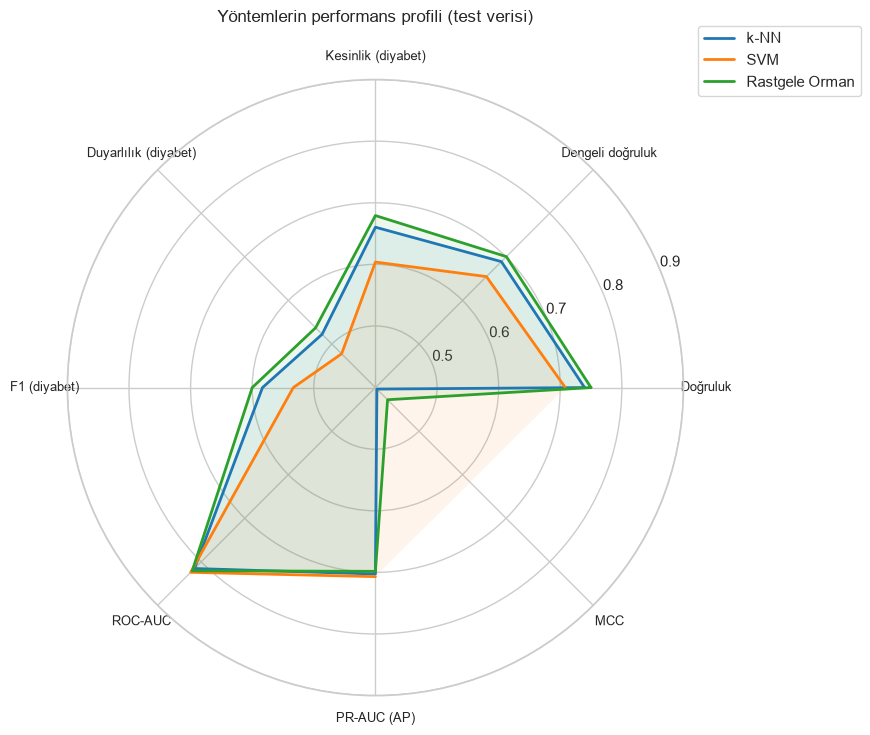

In [44]:
kategoriler = ["Doğruluk", "Dengeli doğruluk", "Kesinlik (diyabet)", "Duyarlılık (diyabet)", "F1 (diyabet)", "ROC-AUC", "PR-AUC (AP)", "MCC"]
aci = np.linspace(0, 2 * np.pi, len(kategoriler), endpoint=False).tolist()
aci += aci[:1]
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"polar": True})
for ad in modeller:
    d = karsilastirma.loc[ad, kategoriler].tolist()
    d += d[:1]
    ax.plot(aci, d, linewidth=2, color=RENK_YONTEM[ad], label=ad)
    ax.fill(aci, d, alpha=0.08, color=RENK_YONTEM[ad])
ax.set_xticks(aci[:-1], kategoriler, fontsize=9)
ax.set_ylim(0.4, 0.9)
ax.set_title("Yöntemlerin performans profili (test verisi)", y=1.08)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
plt.show()

In [45]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=7)
olcut_cv = {"Doğruluk": "accuracy", "Dengeli doğruluk": "balanced_accuracy", "F1 (diyabet)": "f1",
            "Duyarlılık (diyabet)": "recall", "Kesinlik (diyabet)": "precision", "ROC-AUC": "roc_auc"}
cv_sonuc = {}
for ad, m in modeller.items():
    cv_sonuc[ad] = cross_validate(m, X, y, cv=rcv, scoring=olcut_cv, n_jobs=-1)

cv_ozet = pd.DataFrame({ad: {f"{o} (ort ± std)": f"{r['test_' + o].mean():.4f} ± {r['test_' + o].std():.4f}"
                             for o in olcut_cv} for ad, r in cv_sonuc.items()}).T
cv_ozet

,Doğruluk (ort ± std),Dengeli doğruluk (ort ± std),F1 (diyabet) (ort ± std),Duyarlılık (diyabet) (ort ± std),Kesinlik (diyabet) (ort ± std),ROC-AUC (ort ± std)
k-NN,0.7553 ± 0.0270,0.7092 ± 0.0299,0.6122 ± 0.0458,0.5562 ± 0.0639,0.6897 ± 0.0634,0.8279 ± 0.0298
SVM,0.7676 ± 0.0304,0.7166 ± 0.0331,0.6214 ± 0.0496,0.5478 ± 0.0554,0.7236 ± 0.0690,0.8402 ± 0.0301
Rastgele Orman,0.7594 ± 0.0321,0.7170 ± 0.0333,0.6255 ± 0.0473,0.5767 ± 0.0578,0.6899 ± 0.0702,0.8401 ± 0.0325


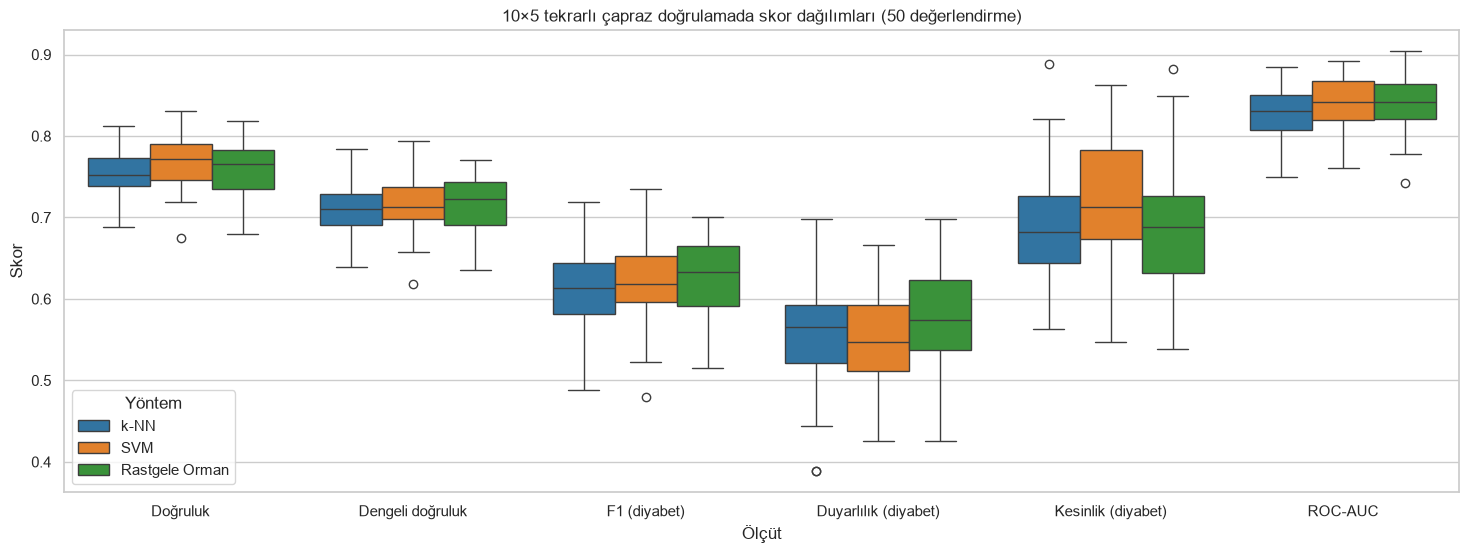

In [46]:
uzun = pd.concat([pd.DataFrame({"Yöntem": ad, "Ölçüt": o, "Skor": r["test_" + o]})
                  for ad, r in cv_sonuc.items() for o in olcut_cv])
plt.figure(figsize=(18, 6))
sns.boxplot(data=uzun, x="Ölçüt", y="Skor", hue="Yöntem", palette=RENK_YONTEM)
plt.title("10×5 tekrarlı çapraz doğrulamada skor dağılımları (50 değerlendirme)")
plt.show()

In [47]:
def duzeltilmis_t(a, b, n_egitim, n_test, k=50):
    d = a - b
    var = d.var(ddof=1) * (1 / k + n_test / n_egitim)
    t = d.mean() / np.sqrt(var)
    return d.mean(), t, 2 * stats.t.sf(abs(t), k - 1)

ad_list = list(modeller)
n_te = len(X) // 5
n_tr = len(X) - n_te
testler = []
for o in ["roc_auc", "f1", "accuracy"]:
    olc = [k for k, v in olcut_cv.items() if v == o][0]
    fr = stats.friedmanchisquare(*[cv_sonuc[a]["test_" + olc] for a in ad_list])
    testler.append({"Ölçüt": olc, "Karşılaştırma": "Friedman (3 yöntem)", "Ort. fark": np.nan,
                    "İstatistik": fr.statistic, "p-değeri": fr.pvalue})
    for i in range(3):
        for j in range(i + 1, 3):
            fark, t, p = duzeltilmis_t(cv_sonuc[ad_list[i]]["test_" + olc], cv_sonuc[ad_list[j]]["test_" + olc], n_tr, n_te)
            testler.append({"Ölçüt": olc, "Karşılaştırma": f"{ad_list[i]} − {ad_list[j]}", "Ort. fark": fark,
                            "İstatistik": t, "p-değeri": p})
testler = pd.DataFrame(testler)
testler["Anlamlı mı? (α=0.05)"] = np.where(testler["p-değeri"] < 0.05, "Evet", "Hayır")
testler.set_index(["Ölçüt", "Karşılaştırma"])

Ort. fark  İstatistik  p-değeri  \
Ölçüt        Karşılaştırma                                            
ROC-AUC      Friedman (3 yöntem)          NaN     23.5600    0.0000   
             k-NN − SVM               -0.0124     -1.4324    0.1584   
             k-NN − Rastgele Orman    -0.0122     -1.4070    0.1657   
             SVM − Rastgele Orman      0.0001      0.0156    0.9876   
F1 (diyabet) Friedman (3 yöntem)          NaN      3.3600    0.1864   
             k-NN − SVM               -0.0091     -0.4076    0.6854   
             k-NN − Rastgele Orman    -0.0133     -0.6064    0.5471   
             SVM − Rastgele Orman     -0.0041     -0.2057    0.8379   
Doğruluk     Friedman (3 yöntem)          NaN      7.3405    0.0255   
             k-NN − SVM               -0.0122     -0.9607    0.3414   
             k-NN − Rastgele Orman    -0.0040     -0.2973    0.7675   
             SVM − Rastgele Orman      0.0082      0.6291    0.5322   

                                   Anlamlı mı? (α=0.05)  
Ölçüt        Karşılaştırma                               
ROC-AUC      Friedman (3 yöntem)                   Evet  
             k-NN − SVM                           Hayır  
             k-NN − Rastgele Orman                Hayır  
             SVM − Rastgele Orman                 Hayır  
F1 (diyabet) Friedman (3 yöntem)                  Hayır  
             k-NN − SVM                           Hayır  
             k-NN − Rastgele Orman                Hayır  
             SVM − Rastgele Orman                 Hayır  
Doğruluk     Friedman (3 yöntem)                   Evet  
             k-NN − SVM                           Hayır  
             k-NN − Rastgele Orman                Hayır  
             SVM − Rastgele Orman                 Hayır

In [48]:
mc = []
for i in range(3):
    for j in range(i + 1, 3):
        a_dogru = tahminler[ad_list[i]] == y_test.values
        b_dogru = tahminler[ad_list[j]] == y_test.values
        tablo = [[np.sum(a_dogru & b_dogru), np.sum(a_dogru & ~b_dogru)],
                 [np.sum(~a_dogru & b_dogru), np.sum(~a_dogru & ~b_dogru)]]
        r = mcnemar(tablo, exact=True)
        mc.append({"Yöntem A": ad_list[i], "Yöntem B": ad_list[j], "İkisi de doğru": tablo[0][0],
                   "Yalnız A doğru": tablo[0][1], "Yalnız B doğru": tablo[1][0], "İkisi de yanlış": tablo[1][1],
                   "McNemar p-değeri": r.pvalue, "Anlamlı mı? (α=0.05)": "Evet" if r.pvalue < 0.05 else "Hayır"})
pd.DataFrame(mc)

,Yöntem A,Yöntem B,İkisi de doğru,Yalnız A doğru,Yalnız B doğru,İkisi de yanlış,McNemar p-değeri,Anlamlı mı? (α=0.05)
0,k-NN,SVM,131,11,5,45,0.2101,Hayır
1,k-NN,Rastgele Orman,136,6,8,42,0.7905,Hayır
2,SVM,Rastgele Orman,134,2,10,46,0.0386,Evet


In [49]:
cv_ort = pd.DataFrame({ad: {o: r["test_" + o].mean() for o in olcut_cv} for ad, r in cv_sonuc.items()}).T
sira_cv = cv_ort.rank(ascending=False, axis=0).add_prefix("CV: ")
sira_test = karsilastirma[["Doğruluk", "Dengeli doğruluk", "F1 (diyabet)", "Duyarlılık (diyabet)",
                           "ROC-AUC", "PR-AUC (AP)", "MCC"]].rank(ascending=False, axis=0).add_prefix("Test: ")
siralama = pd.concat([sira_cv, sira_test], axis=1)
siralama["Ortalama sıra"] = siralama.mean(axis=1)
siralama["Birincilik sayısı"] = (siralama.drop(columns="Ortalama sıra") == 1).sum(axis=1)
siralama = siralama.sort_values("Ortalama sıra")
EN_IYI = siralama.index[0]
display(siralama.style.background_gradient(cmap="RdYlGn_r", vmin=1, vmax=3,
                                            subset=siralama.columns[:-2]).format("{:.2f}"))
print(f"\n>>> Ortalama sıralamaya göre en iyi yöntem: {EN_IYI} <<<")

,CV: Doğruluk,CV: Dengeli doğruluk,CV: F1 (diyabet),CV: Duyarlılık (diyabet),CV: Kesinlik (diyabet),CV: ROC-AUC,Test: Doğruluk,Test: Dengeli doğruluk,Test: F1 (diyabet),Test: Duyarlılık (diyabet),Test: ROC-AUC,Test: PR-AUC (AP),Test: MCC,Ortalama sıra,Birincilik sayısı
Rastgele Orman,2.00,1.00,1.00,1.00,2.00,2.00,1.00,1.00,1.00,1.00,2.00,3.00,1.00,1.46,8.00
SVM,1.00,2.00,2.00,3.00,1.00,1.00,3.00,3.00,3.00,3.00,1.00,1.00,3.00,2.08,5.00
k-NN,3.00,3.00,3.00,2.00,3.00,3.00,2.00,2.00,2.00,2.00,3.00,2.00,2.00,2.46,0.00



>>> Ortalama sıralamaya göre en iyi yöntem: Rastgele Orman <<<


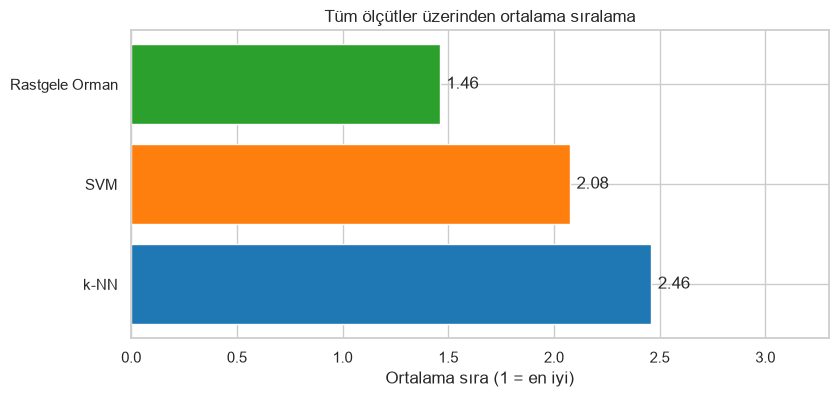

In [50]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(siralama.index[::-1], siralama["Ortalama sıra"][::-1], color=[RENK_YONTEM[a] for a in siralama.index[::-1]])
for i, v in enumerate(siralama["Ortalama sıra"][::-1]):
    ax.text(v + 0.03, i, f"{v:.2f}", va="center")
ax.set_xlim(0, 3.3)
ax.set_xlabel("Ortalama sıra (1 = en iyi)")
ax.set_title("Tüm ölçütler üzerinden ortalama sıralama")
plt.show()